# UCSD Get It Done capstone: intake returns and administrative lifetimes

**Question:** Do cases whose recorded `Case Reason` is `Send back to intake` have longer administrative lifetimes than comparable cases without that label?

This notebook reads **every row of the original `gid_cases.csv`**. It needs no prior notebook, cleaned dataset, saved model, or helper script. All cleaning, comparison definitions, tables, inline charts, statistical methods, validation, and final findings are included here. Put the CSV beside the notebook, or set `GID_CASES_PATH` before starting the kernel. Run **Restart Kernel and Run All**. Required packages: Python 3.10+, pandas, numpy, scipy, matplotlib, and IPython. The source is approximately 5.3 GB; chunked reading and categorical storage reduce memory use. Allow several minutes and several GB of available RAM.

**Interpretation throughout:** the exposure is a reason recorded in an extract, not a verified routing error or an observed intake-return event. Administrative closure is the interval from `Created Date` to a usable `Closed Date` on a case with `Closed = TRUE`. It does not establish physical completion, time spent at intake, the time of a handoff, or an effect caused by returning to intake. Results describe associations in this extract.

## Design and estimands

1. Preserve recorded service groups exactly using `Record Type for ET`. Check agreement with `Resident Case Record Type`. Names containing **Closed Case** are retained; conditioning on these labels can condition on case state. A separately labeled family sensitivity merges only the literal suffix ` Closed Case`.
2. Define report category from `Case Type`, falling back to `Report Type ET`, then `Problem Category`. Prefix values with their source field so unrelated code systems are never silently combined. Preserve all three original columns. Treat missing covariates as explicit strata and test an alternative category definition and complete covariates.
3. Primary references are non-return cases **excluding `Case Reason = Other Department`**. `Other Department` is a reason in this file, not a service group. Missing reasons are allowed in the primary reference and excluded in a sensitivity.
4. Exact strata are **recorded service group × report category × priority × submission channel (`Case Origin`) × creation year**. Retain strata with at least **5 returns and 20 references**. Use all cases in those strata; no random control sampling. Standardize reference outcomes to the return-case stratum distribution. This targets returns with common support, not all returns or all City cases.
5. For closure-time comparisons, additionally require at least **3 usable return closures and 10 usable reference closures per stratum**. Both arms are standardized to the distribution of **all return cases in these time-supported strata**, including open cases in those strata. The resulting duration distribution remains conditional on observed administrative closure. It does not recover the missing lifetime of an open case.
6. Report open and unusable-outcome rates on **all matched cases**, then show closure times on the smaller outcome-supported sample. Examine status, staff text, referral data, closure dispositions, creation cohorts, and stricter temporal matching. No single observation cutoff is presumed.

Thresholds balance overlap and stability for a rare label. A volume-supported service-group duration contrast requires at least **50 usable return closures, 200 reference closures, and 75 return cases in time-supported strata**. Show other estimates as exploratory; prioritize counts and uncertainty over extreme means.

In [1]:
from pathlib import Path
from collections import Counter
import os, sys, time, json, gc, platform, textwrap
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown, HTML

DATA = Path(os.environ.get('GID_CASES_PATH', 'gid_cases.csv')).expanduser().resolve()
assert DATA.is_file(), f'Original source CSV not found: {DATA}'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi':115, 'figure.figsize':(11,5), 'font.size':10,
    'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'semibold',
    'axes.titlepad':14,'axes.grid':True,'grid.alpha':.18,'axes.axisbelow':True,
    'savefig.bbox':'tight'})
RETURN='#C66B2D'; REFERENCE='#187F86'; NEUTRAL='#526579'
def table(frame, caption=None):
    if caption: display(Markdown('**'+caption+'**'))
    z=frame.copy()
    fmt={c: ('{:,.0f}' if any(k in str(c) for k in ['cases','_n','closures','eligible','matched','strata','count'])
                   and not any(k in str(c) for k in ['pct','mean','median','p90','effective']) else '{:,.2f}')
         for c in z.select_dtypes(include='number').columns}
    display(z.style.format(fmt,na_rep='—').set_properties(**{'text-align':'left'})
            .set_table_styles([{'selector':'th','props':[('text-align','left'),('background','#EDF3F5')]},
                              {'selector':'td','props':[('padding','6px 10px')]}]))

print('Source:',DATA.name,'| bytes:',f'{DATA.stat().st_size:,}')
print('Python',platform.python_version(),'pandas',pd.__version__,'numpy',np.__version__,
      'scipy',scipy.__version__,'matplotlib',matplotlib.__version__)

Source: gid_cases.csv | bytes: 5,291,012,190
Python 3.12.8 pandas 3.0.1 numpy 2.2.6 scipy 1.15.3 matplotlib 3.10.0


## 1. Load and clean the complete source

Read selected relevant columns from all rows; irrelevant maps, photos, addresses, and long public descriptions are not needed for this question. Preserve case and parent identifiers, all source category/group fields used here, statuses, reasons, actions, referrals, timestamps, and reported age fields. Blank/whitespace strings become missing. Priority codes remain distinct; no unsupported mapping of numeric priorities to named levels is imposed. Parse dates in their recorded, timezone-naive form; no timezone is supplied in the source.

Low-cardinality strings and repeated staff messages are encoded losslessly as categoricals while reading chunks. Malformed CSV rows raise an error rather than being skipped. Audit missing timestamps separately from parse failures. Duplicate nonmissing Case IDs, if any, retain the row with the latest `Last Modified Date` (source order breaks ties); missing IDs are retained as distinct source rows. No case is dropped merely for being open or lacking a closure date. Timestamp anomalies are flagged, not repaired with the stored age fields.

In [2]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import time, json, gc

CATS = ['Record Type for ET','Resident Case Record Type','Problem Group','Case Type',
        'Problem Category','Report Type ET','Status','Closed','Case Reason','Priority',
        'Case Origin','Action Taken','Action Taken 2','Display Referral Information',
        'Referred Department','Referral Email Name','Referred Email Update','Parent Status',
        'Service Type','Current Type','Original Type','Problem Type','Mobile/Web Status']
IDS = ['Case ID','Case Number','Parent Case ID','Parent Case Number']
DATES = ['Created Date','Closed Date','Last Modified Date','SystemModstamp']
NUMS = ['Days Old','Total Days Open']
COLS = CATS + IDS + DATES + NUMS

def load_source(path=DATA, verbose=True):
    maps = {c:{} for c in CATS}
    pieces = {c:[] for c in COLS}
    audit = Counter()
    start = time.time()
    for i, chunk in enumerate(pd.read_csv(path, usecols=COLS, dtype='string', chunksize=100_000,
                                         keep_default_na=False, na_values=['']), 1):
        audit['raw_rows'] += len(chunk)
        for c in CATS + IDS:
            chunk[c] = chunk[c].str.strip().replace('', pd.NA)
        for c in CATS:
            codes, vals = pd.factorize(chunk[c], sort=False)
            lookup = maps[c]
            translate = np.array([lookup.setdefault(v, len(lookup)) for v in vals], dtype=np.int32)
            out = np.full(len(chunk), -1, dtype=np.int32)
            ok = codes >= 0
            out[ok] = translate[codes[ok]]
            pieces[c].append(out)
        for c in IDS:
            pieces[c].append(chunk[c].to_numpy(dtype=object, na_value=None))
        for c in DATES:
            parsed = pd.to_datetime(chunk[c], format='%Y-%m-%d %H:%M:%S.%f', errors='coerce')
            audit[c + ' raw missing'] += int(chunk[c].isna().sum())
            audit[c + ' parse failures'] += int((chunk[c].notna() & parsed.isna()).sum())
            pieces[c].append(parsed.to_numpy(dtype='datetime64[ns]'))
        for c in NUMS:
            pieces[c].append(pd.to_numeric(chunk[c], errors='coerce').to_numpy(dtype='float32', na_value=np.nan))
        if verbose and i % 10 == 0:
            print(f"Read {audit['raw_rows']:,} source rows in {time.time()-start:.0f}s", flush=True)
    del chunk
    columns = {}
    for c in COLS:
        values = np.concatenate(pieces.pop(c))
        if c in CATS:
            columns[c] = pd.Categorical.from_codes(values, categories=list(maps[c]))
        else:
            columns[c] = values
    frame = pd.DataFrame(columns, copy=False)
    frame.index.name = 'source_row_zero_based'
    del columns, pieces, maps
    gc.collect()
    if verbose:
        print(f'Loaded {len(frame):,} rows; {frame.memory_usage(deep=True).sum()/1e9:.2f} GB; {time.time()-start:.0f}s', flush=True)
    return frame, dict(audit)

In [3]:
started=time.time()
d, load_audit=load_source(DATA)
source_rows=len(d)
duplicate_id=d['Case ID'].notna() & d['Case ID'].duplicated(keep=False)
duplicate_rows=int(duplicate_id.sum())
drop_index=[]
if duplicate_rows:
    dup=d.loc[duplicate_id].sort_values('Last Modified Date',kind='stable',na_position='first')
    drop_index=dup.index[dup['Case ID'].duplicated(keep='last')].tolist()
    d=d.drop(index=drop_index)
d.index.name='source_row_zero_based'
clean_audit=pd.DataFrame({'measure':['Source rows','Duplicate-ID rows before deduplication','Rows removed by ID rule',
    'Retained cases','Missing Case ID','Missing Case Number','Missing parent ID'],
    'count':[source_rows,duplicate_rows,len(drop_index),len(d),d['Case ID'].isna().sum(),
             d['Case Number'].isna().sum(),d['Parent Case ID'].isna().sum()]})
table(clean_audit)
table(pd.DataFrame(load_audit.items(),columns=['timestamp/source measure','count']))
table(d[['Created Date','Closed Date','Last Modified Date','SystemModstamp']].agg(['min','max']),
      'Recorded timestamp ranges; these do not establish an export cutoff')
print('Load and cleaning seconds:',round(time.time()-started,1))

Read 1,000,000 source rows in 14s


Read 2,000,000 source rows in 28s


Read 3,000,000 source rows in 41s


Read 4,000,000 source rows in 55s


Loaded 4,312,496 rows; 1.13 GB; 62s


,measure,count
0,Source rows,"4,312,496"
1,Duplicate-ID rows before deduplication,0
2,Rows removed by ID rule,0
3,Retained cases,"4,312,496"
4,Missing Case ID,0
5,Missing Case Number,0
6,Missing parent ID,"3,869,857"


,timestamp/source measure,count
0,raw_rows,"4,312,496"
1,Created Date raw missing,0
2,Created Date parse failures,0
3,Closed Date raw missing,"379,637"
4,Closed Date parse failures,0
5,Last Modified Date raw missing,0
6,Last Modified Date parse failures,0
7,SystemModstamp raw missing,0
8,SystemModstamp parse failures,0


**Recorded timestamp ranges; these do not establish an export cutoff**

,Created Date,Closed Date,Last Modified Date,SystemModstamp
min,2016-05-18 17:40:57,2016-05-18 17:40:57,2016-05-18 17:40:57,2016-05-18 17:40:58
max,2026-10-26 08:58:58,2026-10-26 09:02:49,2026-10-26 09:02:55,2026-10-26 09:02:55


Load and cleaning seconds: 63.5


In [4]:
import numpy as np
import pandas as pd
from scipy import stats

MISSING = '(missing)'
KEYS = ['service_group', 'report_category', 'priority', 'channel', 'creation_year']

def filled_category(series):
    return series.cat.add_categories([MISSING]).fillna(MISSING) if isinstance(series.dtype, pd.CategoricalDtype) else series.fillna(MISSING).astype('category')

def prepare_cases(d):
    # Raw coded fields stay in d. Derived variables never overwrite their source fields.
    a = pd.DataFrame(index=d.index)
    a['service_group'] = filled_category(d['Record Type for ET'])
    report = pd.Series(MISSING, index=d.index, dtype=object)
    for col in ['Problem Category', 'Report Type ET', 'Case Type']:
        ok = d[col].notna()
        report.loc[ok] = col + ': ' + d.loc[ok, col].astype('string')
    a['report_category'] = report.astype('category')
    del report
    a['priority'] = filled_category(d['Priority'])
    a['channel'] = filled_category(d['Case Origin'])
    a['creation_year'] = d['Created Date'].dt.year.fillna(-1).astype('int16')
    a['return_to_intake'] = d['Case Reason'].astype('string').str.casefold().eq('send back to intake').fillna(False).to_numpy(dtype=bool)
    a['other_department'] = d['Case Reason'].eq('Other Department').to_numpy()
    a['known_reason'] = d['Case Reason'].notna().to_numpy()
    a['closed'] = d['Closed'].eq('TRUE').to_numpy()
    a['open'] = d['Closed'].eq('FALSE').to_numpy()
    a['unknown_state'] = ~(a['closed'] | a['open'])
    elapsed = (d['Closed Date'] - d['Created Date']).dt.total_seconds() / 86400
    a['no_usable_date'] = ~(elapsed.notna() & elapsed.ge(0))
    a['closed_missing_date'] = a['closed'] & a['no_usable_date']
    a['duration_days'] = elapsed.where(a['closed'] & ~a['no_usable_date'])
    a['outcome_unavailable'] = a['duration_days'].isna()
    a['created'] = d['Created Date']
    a['last_modified'] = d['Last Modified Date']
    a['has_parent'] = d['Parent Case ID'].notna().to_numpy()
    a['has_referral'] = d[['Referred Department','Display Referral Information','Referred Email Update']].notna().any(axis=1).to_numpy()
    a['status'] = d['Status']
    return a

def raw_summary(x):
    y = x['duration_days'].dropna()
    return pd.Series({'cases':len(x), 'open_pct':100*x['open'].mean(),
        'no_usable_date_pct':100*x['no_usable_date'].mean(),
        'outcome_unavailable_pct':100*x['outcome_unavailable'].mean(),
        'closed_missing_date_n':int(x['closed_missing_date'].sum()),
        'usable_closures':len(y), 'median_days':y.median(), 'mean_days':y.mean(),
        'p90_days':y.quantile(.9)})

def match_cases(a, reference='primary', min_return=5, min_control=20, extra_keys=None,
                eligible=None, service_family=False, case_type_only=None):
    keep = pd.Series(True,index=a.index) if eligible is None else eligible.copy()
    is_t = a['return_to_intake']
    control = ~is_t
    if reference != 'all_non_return':
        control &= ~a['other_department']
    if reference == 'known_reason':
        control &= a['known_reason']
    if reference == 'no_referral':
        control &= ~a['has_referral']
    x = a.loc[keep & (is_t | control)].copy()
    if service_family:
        x['service_group'] = x['service_group'].astype('string').str.replace(' Closed Case','',regex=False).astype('category')
    if case_type_only is not None:
        x['report_category'] = filled_category(case_type_only.loc[x.index])
    keys = KEYS + (extra_keys or [])
    n = x.groupby(keys+['return_to_intake'], observed=True, dropna=False).size().unstack(fill_value=0)
    n = n.reindex(columns=[False,True],fill_value=0).rename(columns={False:'control_n',True:'return_n'})
    n.index.names = keys
    support = n[(n['return_n']>=min_return)&(n['control_n']>=min_control)].reset_index()
    support['stratum'] = np.arange(len(support))
    m = x.reset_index().merge(support,on=keys,how='inner',validate='many_to_one').set_index(a.index.name or 'index')
    by_group = x.groupby(['service_group','return_to_intake'],observed=True).size().unstack(fill_value=0).reindex(columns=[False,True],fill_value=0)
    matched = m.groupby(['service_group','return_to_intake'],observed=True).size().unstack(fill_value=0).reindex(columns=[False,True],fill_value=0)
    flow = by_group.rename(columns={False:'eligible_control',True:'eligible_return'}).join(matched.rename(columns={False:'matched_control',True:'matched_return'})).fillna(0)
    for arm in ['return','control']:
        flow[f'unmatched_{arm}'] = flow[f'eligible_{arm}']-flow[f'matched_{arm}']
    flow['return_retained_pct'] = 100*flow['matched_return']/flow['eligible_return'].replace(0,np.nan)
    return m, support, flow

def weighted_quantile(values, weights, q):
    order=np.argsort(values)
    v=np.asarray(values)[order]; w=np.asarray(weights)[order]
    # Interpolate the weighted midpoint CDF; uniform weights reproduce the usual median.
    return np.interp(q*np.sum(w),np.cumsum(w)-0.5*w,v)

def compare_matched(m, time_min_return=3, time_min_control=10):
    if m.empty:
        return pd.DataFrame(),pd.DataFrame(),pd.DataFrame(),m.copy()
    n=m.groupby(['stratum','return_to_intake'],observed=True).size().unstack(fill_value=0)
    target=n[True]
    rates=[]; times=[]; differences=[]
    for group, g in [('All supported groups',m), *list(m.groupby('service_group',observed=True))]:
        for arm,label in [(True,'Intake return'),(False,'Reference')]:
            z=g[g['return_to_intake'].eq(arm)]
            w=z['stratum'].map(target)/z['stratum'].map(n[arm])
            row={'service_group':group,'arm':label,**raw_summary(z).to_dict()}
            for c in ['open','no_usable_date','outcome_unavailable','closed_missing_date']:
                row['adjusted_'+c+'_pct']=100*np.average(z[c],weights=w)
            row['effective_n'] = w.sum()**2/(w*w).sum()
            rates.append(row)
    closed=m.loc[m['duration_days'].notna()]
    cn=closed.groupby(['stratum','return_to_intake'],observed=True).size().unstack(fill_value=0).reindex(columns=[False,True],fill_value=0)
    supported=cn.index[(cn[True]>=time_min_return)&(cn[False]>=time_min_control)]
    z=closed[closed['stratum'].isin(supported)].copy()
    z['weight']=z['stratum'].map(target)/np.where(z['return_to_intake'],z['stratum'].map(cn[True]),z['stratum'].map(cn[False]))
    time_all=m[m['stratum'].isin(supported)]
    for group, g in [('All supported groups',z), *list(z.groupby('service_group',observed=True))]:
        arm_stats={}
        for arm,label in [(True,'Intake return'),(False,'Reference')]:
            q=g[g['return_to_intake'].eq(arm)]
            if q.empty: continue
            y=q['duration_days'].to_numpy(); w=q['weight'].to_numpy()
            base=time_all if group=='All supported groups' else time_all[time_all['service_group'].eq(group)]
            row={'service_group':group,'arm':label,'closed_n':len(q),'time_target_all_cases':len(base[base['return_to_intake'].eq(arm)]),
                 'unadjusted_mean_days':y.mean(),'unadjusted_median_days':np.median(y),'unadjusted_p90_days':np.quantile(y,.9),
                 'adjusted_mean_days':np.average(y,weights=w),'adjusted_median_days':weighted_quantile(y,w,.5),
                 'adjusted_p90_days':weighted_quantile(y,w,.9),'effective_closed_n':w.sum()**2/(w*w).sum()}
            times.append(row);arm_stats[arm]=row
        if len(arm_stats)!=2:continue
        s=g.groupby(['stratum','return_to_intake'],observed=True)['duration_days'].agg(['size','mean','var']).unstack('return_to_intake')
        ws=target.reindex(s.index);ws=ws/ws.sum()
        variance=np.sum(ws**2*(s[('var',True)]/s[('size',True)]+s[('var',False)]/s[('size',False)]))
        delta=arm_stats[True]['adjusted_mean_days']-arm_stats[False]['adjusted_mean_days']
        se=np.sqrt(variance)
        r={'service_group':group,'time_strata':len(s),'return_closed_n':arm_stats[True]['closed_n'],
           'reference_closed_n':arm_stats[False]['closed_n'],'time_target_return_n':arm_stats[True]['time_target_all_cases'],
           'unadjusted_mean_diff':arm_stats[True]['unadjusted_mean_days']-arm_stats[False]['unadjusted_mean_days'],
           'adjusted_mean_diff':delta,'ci_low':delta-1.96*se,'ci_high':delta+1.96*se,
           'adjusted_median_diff':arm_stats[True]['adjusted_median_days']-arm_stats[False]['adjusted_median_days'],
           'adjusted_p90_diff':arm_stats[True]['adjusted_p90_days']-arm_stats[False]['adjusted_p90_days'],
           'p_value':2*stats.norm.sf(abs(delta/se)) if se>0 else np.nan}
        differences.append(r)
    diffs=pd.DataFrame(differences)
    if not diffs.empty:
        diffs['substantial_sample']=(diffs['return_closed_n']>=50)&(diffs['reference_closed_n']>=200)&(diffs['time_target_return_n']>=75)
        diffs['fdr_q']=np.nan
        mask=diffs['substantial_sample']&diffs['service_group'].ne('All supported groups')
        if mask.any():
            p=diffs.loc[mask,'p_value'].to_numpy();order=np.argsort(p)
            adj=np.minimum.accumulate((p[order]*len(p)/np.arange(1,len(p)+1))[::-1])[::-1].clip(0,1)
            inverse=np.empty_like(order);inverse[order]=np.arange(len(order))
            diffs.loc[mask,'fdr_q']=adj[inverse]
    return pd.DataFrame(rates),pd.DataFrame(times),diffs,z

In [5]:
a=prepare_cases(d)
group_agreement=d['Record Type for ET'].astype('string').eq(d['Resident Case Record Type'].astype('string')).fillna(False)
elapsed=(d['Closed Date']-d['Created Date']).dt.total_seconds()/86400
quality=pd.DataFrame({'measure':['Recorded group fields disagree or missing','Negative closure intervals',
    'Closure earlier than creation','Closed TRUE without usable closure date','Closed FALSE with a recorded closure date',
    'Unknown Closed flag','Last Modified Date before Closed Date','Last Modified Date before Created Date',
    'Missing primary Case Type','Missing derived report category','Other Department reasons excluded from primary reference'],
    'count':[(~group_agreement).sum(),elapsed.lt(0).sum(),(d['Closed Date']<d['Created Date']).sum(),
      a.closed_missing_date.sum(),(a.open&d['Closed Date'].notna()).sum(),a.unknown_state.sum(),
      (d['Last Modified Date']<d['Closed Date']).sum(),(d['Last Modified Date']<d['Created Date']).sum(),
      d['Case Type'].isna().sum(),a.report_category.eq(MISSING).sum(),a.other_department.sum()]})
table(quality)
table(pd.crosstab(d['Status'],d['Closed']).reset_index(), 'Recorded Status versus Closed flag (all cases)')
raw_overview=pd.DataFrame([{'arm':label,**raw_summary(a.loc[a.return_to_intake.eq(arm)]).to_dict()}
                           for arm,label in [(True,'Intake return'),(False,'All non-return')]])
table(raw_overview,'All cases before comparison restrictions')
intake_cases=d.loc[a.return_to_intake].join(a.loc[a.return_to_intake,['report_category','duration_days','open','outcome_unavailable']])
print(f'Identified {len(intake_cases):,} intake-return cases ({100*a.return_to_intake.mean():.4f}% of retained cases).')

,measure,count
0,Recorded group fields disagree or missing,0
1,Negative closure intervals,0
2,Closure earlier than creation,0
3,Closed TRUE without usable closure date,"115,089"
4,Closed FALSE with a recorded closure date,0
5,Unknown Closed flag,0
6,Last Modified Date before Closed Date,"4,795"
7,Last Modified Date before Created Date,0
8,Missing primary Case Type,"2,118,198"
9,Missing derived report category,"1,161,342"


**Recorded Status versus Closed flag (all cases)**

Closed,Status,TRUE,FALSE
0,Closed,"3,648,859.00",0.00
1,Closed - Referred,"392,655.00",0.00
2,Open,0.00,"109,956.00"
3,Denied,0.00,"2,179.00"
4,Cancelled,"6,434.00",0.00
5,Approved,0.00,"9,028.00"
6,In Process,0.00,35.00
7,Completed,0.00,"1,146.00"
8,Recommended for Approval,0.00,371.00
9,District Supervisor Approved,0.00,40.00


**All cases before comparison restrictions**

,arm,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days
0,Intake return,"1,033",41.34,41.34,41.34,0,606,28.73,100.06,288.10
1,All non-return,"4,311,463",6.13,8.80,8.80,"115,089","3,932,253",2.95,43.35,71.43


Identified 1,033 intake-return cases (0.0240% of retained cases).


**Outcome definitions and denominators.** `open_pct` uses `Closed = FALSE`, not a hand-picked list of status names; a status such as `Duplicate` may still have a false closed flag. `no_usable_date_pct` counts missing/invalid `Created Date` or `Closed Date`, or a negative interval, over **all cases**. `outcome_unavailable_pct` additionally disallows durations for cases not recorded closed. `closed_missing_date_n` isolates cases recorded closed but without usable dates. Open cases and missing outcomes can overlap, so their percentages are not additive. Mean, median, and 90th percentile always use usable administrative closures only. Timestamp disagreement between modification and closure is reported because it weakens cutoff inference; it does not by itself invalidate a nonnegative creation-to-closure interval.

`Record Type for ET` and `Resident Case Record Type` are recorded case classifications, not verified owning teams or routing histories. The optional workspace field dictionary was consulted during preparation: these group fields are calculated strings, `Closed` is the boolean IsClosed field, and `Days Old` is calculated. The notebook relies only on the CSV. This supports cautious terminology but does not supply business definitions of intake return or physical completion.

## 2. What does the intake-return label appear to represent?

In [6]:
status_exam=(intake_cases.groupby(['Status','Closed'],observed=True).agg(
    cases=('Case ID','size'),closure_dates=('Closed Date','count'),
    earliest_closure=('Closed Date','min'),latest_closure=('Closed Date','max'))
    .reset_index().sort_values('cases',ascending=False))
table(status_exam,'All intake returns: status, flag, and closure dates')
intake_info=pd.DataFrame({'field':['Action Taken','Action Taken 2','Referred Department','Display Referral Information',
    'Referred Email Update','Referral Email Name','Parent Case ID'],
    'populated_cases':[intake_cases[c].notna().sum() for c in ['Action Taken','Action Taken 2','Referred Department',
      'Display Referral Information','Referred Email Update','Referral Email Name','Parent Case ID']]})
intake_info['populated_pct']=100*intake_info.populated_cases/len(intake_cases)
table(intake_info,'Presence of action, referral, and linkage information')
action_templates=(intake_cases['Action Taken'].astype('string').fillna('(missing)').value_counts()
                  .rename_axis('recorded Action Taken').rename('cases').reset_index())
table(action_templates.head(16),'Most frequent recorded action descriptions (full templates)')
table(intake_cases['Referred Department'].astype('string').fillna('(missing)').value_counts()
      .rename_axis('recorded referral destination').rename('cases').reset_index(), 'Recorded referral destinations')
table(intake_cases['Display Referral Information'].astype('string').dropna().value_counts().head(10)
      .rename_axis('recorded referral message').rename('cases').reset_index(),'Referral-message examples by frequency')

**All intake returns: status, flag, and closure dates**

,Status,Closed,cases,closure_dates,earliest_closure,latest_closure
0,Closed,TRUE,587,587.00,2022-05-02 11:52:44,2026-10-14 07:10:25
2,Open,FALSE,260,0.00,—,—
4,Acknowledged,FALSE,81,0.00,—,—
6,In Progress,FALSE,38,0.00,—,—
3,Duplicate,FALSE,22,0.00,—,—
1,Closed - Referred,TRUE,19,19.00,2022-05-17 15:17:50,2026-08-26 12:51:25
7,Assigned,FALSE,18,0.00,—,—
5,New,FALSE,8,0.00,—,—


**Presence of action, referral, and linkage information**

,field,populated_cases,populated_pct
0,Action Taken,530,51.31
1,Action Taken 2,2,0.19
2,Referred Department,33,3.19
3,Display Referral Information,40,3.87
4,Referred Email Update,33,3.19
5,Referral Email Name,0,0.00
6,Parent Case ID,120,11.62


**Most frequent recorded action descriptions (full templates)**

,recorded Action Taken,cases
0,(missing),503
1,City crews recently resolved the issue or conducted the necessary repairs as reported in your inquiry.,195
2,This issue was recently resolved or repaired.,64
3,This report was forwarded to the appropriate service provider for future follow-up.,54
4,This report was forwarded to the appropriate service provider.,43
5,It was evaluated and determined that no action is warranted by the City of San Diego at this time.,39
6,This duplicate report is being closed. The original report is still open and City crews are actively working towards resolution.,26
7,This issue will be addressed as part of other projects or City work occurring nearby.,20
8,"The reported issue is located on a private or commercial property, or where a City maintenance agreement is required.",16
9,It was evaluated and determined that no action is required by the City of San Diego at this time.,13


**Recorded referral destinations**

,recorded referral destination,cases
0,(missing),"1,000"
1,Caltrans San Diego,9
2,appropriate department or agency,6
3,Water Repair (PUD),4
4,Water Waste Complaints (PUD),2
5,Graffiti – SDGE Poles and Boxes,2
6,AT&T Fix It,2
7,Field Engineering,1
8,Fire Department,1
9,PW Facilities Maintenance,1


**Referral-message examples by frequency**

,recorded referral message,cases
0,This report has been referred to Parks Intake,6
1,This report has been referred to Caltrans San Diego at ct.public.information.d11@dot.ca.gov,6
2,This report has been referred to Water Repair (PUD) at wcm_gid@sandiego.gov,4
3,This report has been referred to T-ROW Code Compliance,3
4,This report has been referred to Water Waste Complaints (PUD) at waterwaste@sandiego.gov,2
5,This report has been referred to Caltrans San Diego at null,2
6,This report has been referred to appropriate department or agency at MichelleM@sandiego.gov,2
7,This report has been referred to AT&T Fix It at attfixit@amcustomercare.att-mail.com,2
8,This report has been referred to Storm Water,1
9,This report has been referred to appropriate department or agency at BrownJR@sandiego.gov,1


**Recorded service groups containing intake returns**

,service_group,cases,return_cases,return_pct
0,Street Division Closed Case,"1,189,013",465,0.04
1,Parks & Recreation,"55,066",306,0.56
2,Storm Water Closed Case,"30,939",103,0.33
3,Street Division,"55,043",92,0.17
4,Storm Water,"27,144",24,0.09
5,ESD Complaint/Report,"1,304,931",13,0.00
6,TSW ROW,"56,290",12,0.02
7,Traffic Engineering Closed Case,"25,857",9,0.03
8,Parking,"511,205",4,0.00
9,EV Charger,14,1,7.14


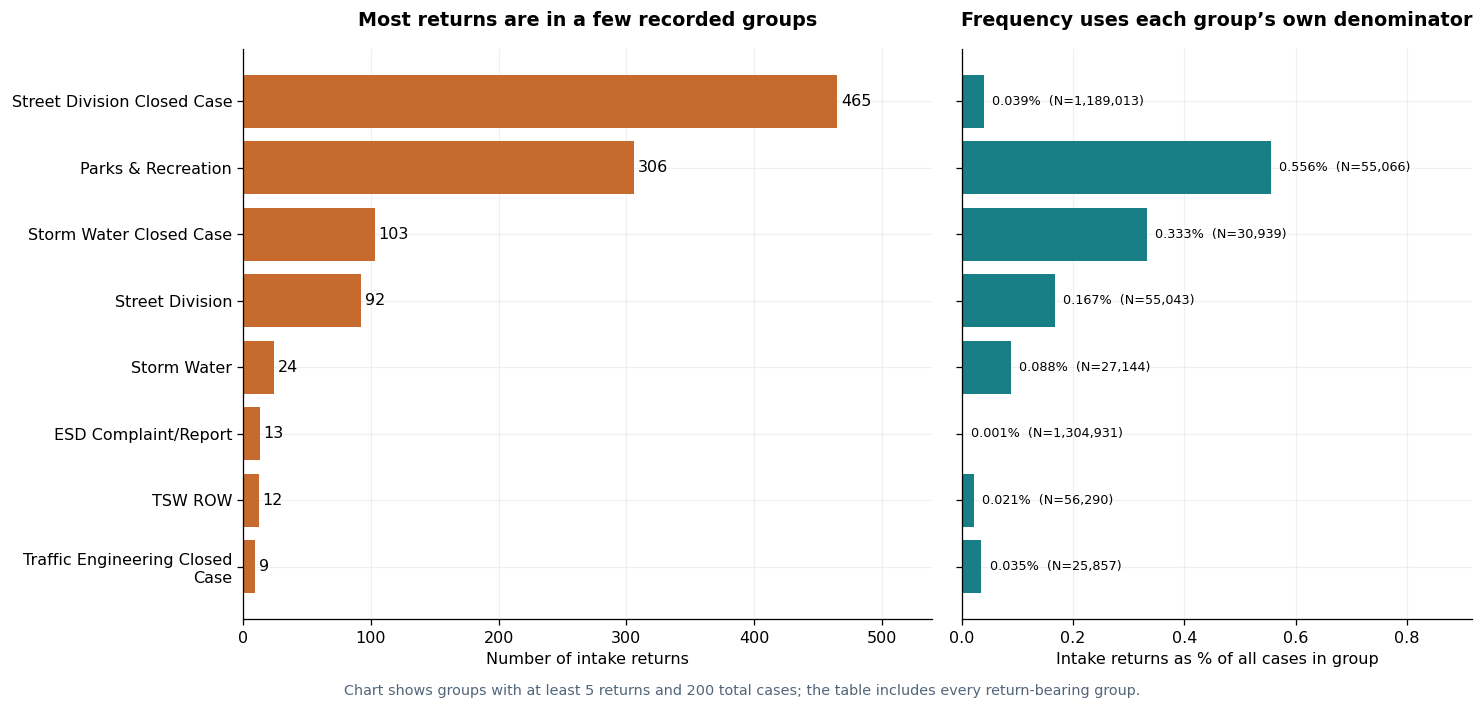

In [7]:
group_frequency=a.groupby('service_group',observed=True).agg(cases=('return_to_intake','size'),
    return_cases=('return_to_intake','sum')).sort_values('return_cases',ascending=False)
group_frequency['return_pct']=100*group_frequency.return_cases/group_frequency.cases
table(group_frequency.loc[group_frequency.return_cases>0].reset_index(),'Recorded service groups containing intake returns')
top=group_frequency.loc[group_frequency.return_cases.ge(5)&group_frequency.cases.ge(200)].head(10).iloc[::-1]
fig,axes=plt.subplots(1,2,figsize=(13,6),gridspec_kw={'width_ratios':[1.35,1]})
y=np.arange(len(top));labels=[textwrap.fill(str(s),28) for s in top.index]
axes[0].barh(y,top.return_cases,color=RETURN);axes[0].set_yticks(y,labels)
axes[0].set_xlabel('Number of intake returns');axes[0].set_title('Most returns are in a few recorded groups')
for i,n in enumerate(top.return_cases):axes[0].text(n+3,i,f'{n:,}',va='center')
axes[1].barh(y,top.return_pct,color=REFERENCE);axes[1].set_yticks(y,[])
axes[1].set_xlabel('Intake returns as % of all cases in group');axes[1].set_title('Frequency uses each group’s own denominator')
for i,(_,r) in enumerate(top.iterrows()):axes[1].text(r.return_pct+.015,i,f'{r.return_pct:.3f}%  (N={int(r.cases):,})',va='center',fontsize=8)
axes[0].set_xlim(0,top.return_cases.max()*1.16);axes[1].set_xlim(0,top.return_pct.max()*1.65)
fig.text(.5,-.015,'Chart shows groups with at least 5 returns and 200 total cases; the table includes every return-bearing group.',
         ha='center',fontsize=9,color=NEUTRAL)
fig.tight_layout();plt.show()

In [8]:
import numpy as np
import pandas as pd

def text_flags(d):
    patterns = {
        'Referral or forwarding': r'referr|forwarded|external system|service provider',
        'Duplicate or linked report': r'duplicate|previously submitted|original report|same issue',
        'No action or jurisdiction limitation': r'no action|not maintained|private (?:or commercial )?property|not within|limited resources|city standards|maintenance agreement',
        'Future work or partial repair': r'future follow|other projects|pending|temporary repair|will be addressed',
        'Repair or resolution language': r'resolved|repaired|necessary repairs|has been addressed|completed',
        'Unable to locate': r'unable to locate|could not locate|not be located',
    }
    flags=pd.DataFrame(index=d.index)
    # Match once per distinct category, then map codes rather than expanding 4.3m texts.
    for label, pattern in patterns.items():
        hit=np.zeros(len(d),dtype=bool)
        for col in ['Action Taken','Action Taken 2']:
            cats=pd.Series(d[col].cat.categories,dtype='string')
            lookup=cats.str.contains(pattern,case=False,regex=True,na=False).to_numpy(dtype=bool)
            code=d[col].cat.codes.to_numpy(); valid=code>=0
            hit[valid] |= lookup[code[valid]]
        flags[label]=hit
    return flags

def derive_disposition(d,a,flags):
    tag=pd.Series('No action text',index=d.index,dtype=object)
    any_text=d['Action Taken'].notna()|d['Action Taken 2'].notna()
    tag.loc[any_text]='Other action text'
    # Precedence is explicit; referral / duplication take priority over repair wording.
    for label in ['Repair or resolution language','Future work or partial repair','Unable to locate',
                  'No action or jurisdiction limitation','Referral or forwarding','Duplicate or linked report']:
        hit=flags[label]
        if label=='Referral or forwarding': hit=hit|a['has_referral']|d['Status'].eq('Closed - Referred')
        if label=='Duplicate or linked report': hit=hit|d['Status'].eq('Duplicate')
        tag.loc[hit]=label
    return tag.astype('category')

In [9]:
theme_flags=text_flags(d)
a['disposition']=derive_disposition(d,a,theme_flags)
theme_table=pd.DataFrame({'staff-text theme':theme_flags.columns,
    'return_cases':[int(theme_flags.loc[a.return_to_intake,c].sum()) for c in theme_flags.columns]})
theme_table['return_pct']=100*theme_table.return_cases/a.return_to_intake.sum()
table(theme_table,'Staff-text themes among intake returns (multiple themes per case allowed)')
table(a.loc[a.return_to_intake].groupby('disposition',observed=True).apply(raw_summary).reset_index(),
      'Text-derived dispositions of intake returns, including open cases')

**Staff-text themes among intake returns (multiple themes per case allowed)**

,staff-text theme,return_cases,return_pct
0,Referral or forwarding,118,11.42
1,Duplicate or linked report,30,2.90
2,No action or jurisdiction limitation,82,7.94
3,Future work or partial repair,81,7.84
4,Repair or resolution language,260,25.17
5,Unable to locate,4,0.39


**Text-derived dispositions of intake returns, including open cases**

,disposition,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days
0,Duplicate or linked report,52,42.31,42.31,42.31,0,30,35.07,78.17,215.32
1,Future work or partial repair,25,12.00,12.00,12.00,0,22,11.68,80.49,137.53
2,No action or jurisdiction limitation,82,0.00,0.00,0.00,0,82,42.39,128.49,420.95
3,No action text,450,78.22,78.22,78.22,0,98,65.71,115.18,368.13
4,Other action text,12,8.33,8.33,8.33,0,11,146.26,219.14,447.80
5,Referral or forwarding,155,30.32,30.32,30.32,0,108,12.90,64.44,212.14
6,Repair or resolution language,253,0.79,0.79,0.79,0,251,23.67,99.30,315.97
7,Unable to locate,4,0.00,0.00,0.00,0,4,57.97,100.79,221.21


**Reading the descriptions.** Common templates mention completed repairs, forwarding for follow-up, duplicate reports, no action warranted, private property, and work deferred to other projects. These are heterogeneous administrative paths. They support investigating handoffs, case-state maintenance, jurisdiction checks, and record linkage. They do not establish that the original assignment was wrong. Missing text and referral fields are substantial; absence of referral metadata is not proof that no handoff occurred. Templates can describe an administrative action without being an individual explanation for the intake return, and the extract does not establish which happened first.

The text-derived disposition classifier above is transparent and exploratory. It uses **Status, Action Taken, Action Taken 2, and referral presence**, never `Case Reason`, so it does not mechanically classify the exposure itself. Its explicit priority is duplicate → referral → no action/jurisdiction → unable to locate → future/partial → repair/resolution → other/no text. Themes may overlap; dispositions are mutually exclusive. Resolution wording is evidence about a message, not independent verification of physical work. Matching on disposition later is a sensitivity to administrative pathways, not adjustment for a proven baseline confounder.

## 3. Exact comparisons, common support, and selection

For stratum (s), let (N_{Ts}) be all matched intake returns and (N_{Cs}) references. Each return gets weight 1; each reference gets (N_{Ts}/N_{Cs}). Standardized percentages therefore compare both arms under the same stratum mix. For durations, let (n_{Ts}, n_{Cs}) be usable closure counts. Each observed return closure gets (N_{Ts}/n_{Ts}), and each reference closure gets (N_{Ts}/n_{Cs}), on time-supported strata only. These weights equalize the stratum mix, **not** the probability of closing within a stratum.

Unadjusted summaries on the matched sample show raw differences before weighting. Additional unadjusted summaries on the time-supported subset keep the duration population fixed when comparing adjusted and unadjusted time estimates. No model extrapolates to unmatched cells. Matching requires the recorded covariates, not verified original covariates at case creation; categories, reason, priority, and group may have changed after a return. Unmeasured complexity, geography, operational workload, historical workflow changes, and overwritten reason codes remain possible selection mechanisms.

In [10]:
m,support,flow=match_cases(a)
rates,times,differences,weighted_closed=compare_matched(m)
table(flow.loc[flow.eligible_return>0].reset_index(),'Eligibility and exact-support attrition by recorded group')
flow_total=flow[['eligible_control','eligible_return','matched_control','matched_return','unmatched_control','unmatched_return']].sum()
table(flow_total.rename_axis('stage').rename('cases').reset_index(),'Complete reference and return flow, including groups without returns')
print(f'{len(support):,} supported all-case strata; {int(m.return_to_intake.sum()):,} matched returns; '
      f'{int((~m.return_to_intake).sum()):,} matched references.')
table(rates[['service_group','arm','cases','open_pct','no_usable_date_pct','outcome_unavailable_pct',
    'closed_missing_date_n','usable_closures','median_days','mean_days','p90_days',
    'adjusted_open_pct','adjusted_no_usable_date_pct','effective_n']],
    'All matched cases: unadjusted closure summaries and standardized availability')
availability_differences=[]
for group,g in rates.groupby('service_group',sort=False):
    r=g.set_index('arm')
    availability_differences.append({'service_group':group,
        'unadjusted_open_diff_pp':r.loc['Intake return','open_pct']-r.loc['Reference','open_pct'],
        'adjusted_open_diff_pp':r.loc['Intake return','adjusted_open_pct']-r.loc['Reference','adjusted_open_pct'],
        'unadjusted_no_usable_date_diff_pp':r.loc['Intake return','no_usable_date_pct']-r.loc['Reference','no_usable_date_pct'],
        'adjusted_no_usable_date_diff_pp':r.loc['Intake return','adjusted_no_usable_date_pct']-r.loc['Reference','adjusted_no_usable_date_pct']})
availability_differences=pd.DataFrame(availability_differences)
table(availability_differences,'Outcome-availability differences (return minus reference, percentage points)')
time_return_n=int(weighted_closed.return_to_intake.sum())
time_target_return_n=int(differences.loc[differences.service_group.eq('All supported groups'),'time_target_return_n'].iloc[0])
table(pd.DataFrame({'stage':['All intake returns','Matched all-case returns','Usable closures among matched returns',
    'All returns in time-supported strata','Usable return closures in time-supported strata'],
    'cases':[int(a.return_to_intake.sum()),int(m.return_to_intake.sum()),int((m.return_to_intake&m.duration_days.notna()).sum()),
             time_target_return_n,time_return_n]}),'Separate duration-analysis attrition')

**Eligibility and exact-support attrition by recorded group**

return_to_intake,service_group,eligible_control,eligible_return,matched_control,matched_return,unmatched_return,unmatched_control,return_retained_pct
0,ESD Complaint/Report,"1,304,642",13,"12,577",5,8,"1,292,065",38.46
1,Storm Water Closed Case,"30,774",103,718,51,52,"30,056",49.51
2,Parks & Recreation,"54,756",306,"18,318",191,115,"36,438",62.42
3,Parking,"510,091",4,0,0,4,"510,091",0.00
4,Neighborhood Policing,"289,376",1,0,0,1,"289,376",0.00
5,TSW ROW,"56,275",12,0,0,12,"56,275",0.00
6,Street Division Closed Case,"1,188,480",465,"131,985",343,122,"1,056,495",73.76
7,DSD,"25,698",1,0,0,1,"25,698",0.00
8,Street Division,"54,950",92,"1,876",44,48,"53,074",47.83
9,Storm Water Code Enforcement,"41,669",1,0,0,1,"41,669",0.00


**Complete reference and return flow, including groups without returns**

,stage,cases
0,eligible_control,"4,308,165"
1,eligible_return,"1,033"
2,matched_control,"165,474"
3,matched_return,634
4,unmatched_control,"4,142,691"
5,unmatched_return,399


37 supported all-case strata; 634 matched returns; 165,474 matched references.


**All matched cases: unadjusted closure summaries and standardized availability**

,service_group,arm,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days,adjusted_open_pct,adjusted_no_usable_date_pct,effective_n
0,All supported groups,Intake return,634,36.28,36.28,36.28,0,404,18.41,77.55,226.30,36.28,36.28,634.00
1,All supported groups,Reference,"165,474",2.09,2.09,2.09,0,"162,021",2.87,25.28,46.29,13.14,13.14,"7,062.12"
2,ESD Complaint/Report,Intake return,5,0.00,0.00,0.00,0,5,11.79,13.90,26.05,0.00,0.00,5.00
3,ESD Complaint/Report,Reference,"12,577",0.06,0.06,0.06,0,"12,570",2.11,9.85,12.75,0.06,0.06,"12,577.00"
4,Storm Water Closed Case,Intake return,51,0.00,0.00,0.00,0,51,54.87,133.34,415.75,0.00,0.00,51.00
5,Storm Water Closed Case,Reference,718,0.00,0.00,0.00,0,718,13.82,78.03,187.29,0.00,0.00,625.19
6,Parks & Recreation,Intake return,191,97.38,97.38,97.38,0,5,28.07,50.01,117.05,97.38,97.38,191.00
7,Parks & Recreation,Reference,"18,318",8.56,8.56,8.56,0,"16,750",9.73,34.68,79.75,20.59,20.59,"4,510.76"
8,Street Division Closed Case,Intake return,343,0.00,0.00,0.00,0,343,15.81,70.58,215.40,0.00,0.00,343.00
9,Street Division Closed Case,Reference,"131,985",0.00,0.00,0.00,0,"131,983",2.64,25.27,42.46,0.00,0.00,"2,796.17"


**Outcome-availability differences (return minus reference, percentage points)**

,service_group,unadjusted_open_diff_pp,adjusted_open_diff_pp,unadjusted_no_usable_date_diff_pp,adjusted_no_usable_date_diff_pp
0,All supported groups,34.19,23.13,34,23
1,ESD Complaint/Report,-0.06,-0.06,-0,-0
2,Storm Water Closed Case,0.00,0.00,0,0
3,Parks & Recreation,88.82,76.79,89,77
4,Street Division Closed Case,-0.00,-0.00,-0,-0
5,Street Division,0.00,0.00,0,0


**Separate duration-analysis attrition**

,stage,cases
0,All intake returns,"1,033"
1,Matched all-case returns,634
2,Usable closures among matched returns,404
3,All returns in time-supported strata,399
4,Usable return closures in time-supported strata,399


In [11]:
retention=[]
for label,sel in [('Retained returns',a.return_to_intake&a.index.isin(m.index)),
                  ('Unmatched returns',a.return_to_intake&~a.index.isin(m.index))]:
    x=a.loc[sel];retention.append({'sample':label,**raw_summary(x).to_dict(),
        'created_2026_pct':100*x.creation_year.eq(2026).mean(),
        'missing_report_category_pct':100*x.report_category.eq(MISSING).mean(),
        'parks_pct':100*x.service_group.eq('Parks & Recreation').mean()})
table(pd.DataFrame(retention),'Selection diagnostics: retained versus unmatched returns')
# Exact balance check for all matching covariates, using the same all-return target.
sn=m.groupby(['stratum','return_to_intake'],observed=True).size().unstack()
control_weights=m.loc[~m.return_to_intake,'stratum'].map(sn[True]/sn[False])
balance=[]
for key in KEYS:
    p=m.loc[m.return_to_intake,key].value_counts(normalize=True)
    c=m.loc[~m.return_to_intake].groupby(key,observed=True).apply(lambda z:control_weights.loc[z.index].sum())
    c=c/c.sum()
    balance.append({'covariate':key,'max_absolute_weighted_share_gap':p.subtract(c,fill_value=0).abs().max()})
balance=pd.DataFrame(balance)
table(balance,'Weighted covariate balance: zero confirms exact standardization on recorded covariates')

**Selection diagnostics: retained versus unmatched returns**

,sample,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days,created_2026_pct,missing_report_category_pct,parks_pct
0,Retained returns,634,36.28,36.28,36.28,0,404,18.41,77.55,226.30,27.13,0.00,30.13
1,Unmatched returns,399,49.37,49.37,49.37,0,202,63.77,145.08,369.29,30.33,0.25,28.82


**Weighted covariate balance: zero confirms exact standardization on recorded covariates**

,covariate,max_absolute_weighted_share_gap
0,service_group,0.00
1,report_category,0.00
2,priority,0.00
3,channel,0.00
4,creation_year,0.00


## 4. Administrative closure time, conditional on observed closure

Durations are in 24-hour days and preserve fractional days and zero-day closures. Means are sensitive to the right tail; medians and 90th percentiles show distribution differences. Weighted quantiles interpolate the weighted midpoint empirical CDF. They need not equal quantiles obtained from averaging stratum quantiles. Reported **differences in medians or 90th percentiles are differences between standardized distributions**, not the median of individual causal effects.

Approximate 95% intervals for adjusted mean differences use


\[
\widehat\Delta=\sum_s w_s(\bar{Y}_{Ts}-\bar{Y}_{Cs}),\quad
\widehat{\mathrm{Var}}(\widehat\Delta)=\sum_s w_s^2\left(\frac{s^2_{Ts}}{n_{Ts}}+\frac{s^2_{Cs}}{n_{Cs}}\right),
\quad w_s=\frac{N_{Ts}}{\sum_jN_{Tj}}.
\]

These are fixed-stratum, independent-case normal approximations describing repeat-sampling uncertainty, not uncertainty about the arithmetic of this full extract. They omit clustering of related reports, reason misclassification, outcome selection, and residual confounding. Small-stratum and skew-tail uncertainty can be understated. Benjamini–Hochberg q-values are shown only for volume-supported primary service-group contrasts; all sensitivity analyses are exploratory. No significance test removes these design limitations.

In [12]:
table(times,'Time-supported sample: raw and standardized closure distributions')
table(differences,'Return minus reference administrative days; approximate intervals, not causal effects')
time_excluded=m.loc[~m.stratum.isin(weighted_closed.stratum.unique())]
table(time_excluded.groupby(['service_group','return_to_intake'],observed=True).apply(raw_summary).reset_index(),
      'Matched cases excluded from time estimates for inadequate observed-closure support')

**Time-supported sample: raw and standardized closure distributions**

,service_group,arm,closed_n,time_target_all_cases,unadjusted_mean_days,unadjusted_median_days,unadjusted_p90_days,adjusted_mean_days,adjusted_median_days,adjusted_p90_days,effective_closed_n
0,All supported groups,Intake return,399,399,77.90,18.14,228.46,77.90,18.14,231.60,399.00
1,All supported groups,Reference,"145,271","145,280",24.20,2.63,37.21,47.81,3.06,142.23,"3,443.13"
2,ESD Complaint/Report,Intake return,5,5,13.90,11.79,26.05,13.90,11.79,27.62,5.00
3,ESD Complaint/Report,Reference,"12,570","12,577",9.85,2.11,12.75,9.85,2.11,12.75,"12,570.00"
4,Storm Water Closed Case,Intake return,51,51,133.34,54.87,415.75,133.34,54.87,423.50,51.00
5,Storm Water Closed Case,Reference,718,718,78.03,13.82,187.29,80.88,13.39,204.19,625.19
6,Street Division Closed Case,Intake return,343,343,70.58,15.81,215.40,70.58,15.81,217.60,343.00
7,Street Division Closed Case,Reference,"131,983","131,985",25.27,2.64,42.46,43.44,2.66,132.81,"2,796.17"


**Return minus reference administrative days; approximate intervals, not causal effects**

,service_group,time_strata,return_closed_n,reference_closed_n,time_target_return_n,unadjusted_mean_diff,adjusted_mean_diff,ci_low,ci_high,adjusted_median_diff,adjusted_p90_diff,p_value,substantial_sample,fdr_q
0,All supported groups,19,399,"145,271",399,53.70,30.09,16.15,44.02,15.07,89.38,0.00,True,—
1,ESD Complaint/Report,1,5,"12,570",5,4.05,4.05,-6.01,14.11,9.68,14.86,0.43,False,—
2,Storm Water Closed Case,5,51,718,51,55.31,52.45,-3.80,108.71,41.48,219.31,0.07,False,—
3,Street Division Closed Case,13,343,"131,983",343,45.31,27.14,13.26,41.03,13.15,84.78,0.00,True,0.00


**Matched cases excluded from time estimates for inadequate observed-closure support**

,service_group,return_to_intake,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days
0,Parks & Recreation,False,"18,318",8.56,8.56,8.56,0,"16,750",9.73,34.68,79.75
1,Parks & Recreation,True,191,97.38,97.38,97.38,0,5,28.07,50.01,117.05
2,Street Division,False,"1,876",100.00,100.00,100.00,0,0,—,—,—
3,Street Division,True,44,100.00,100.00,100.00,0,0,—,—,—


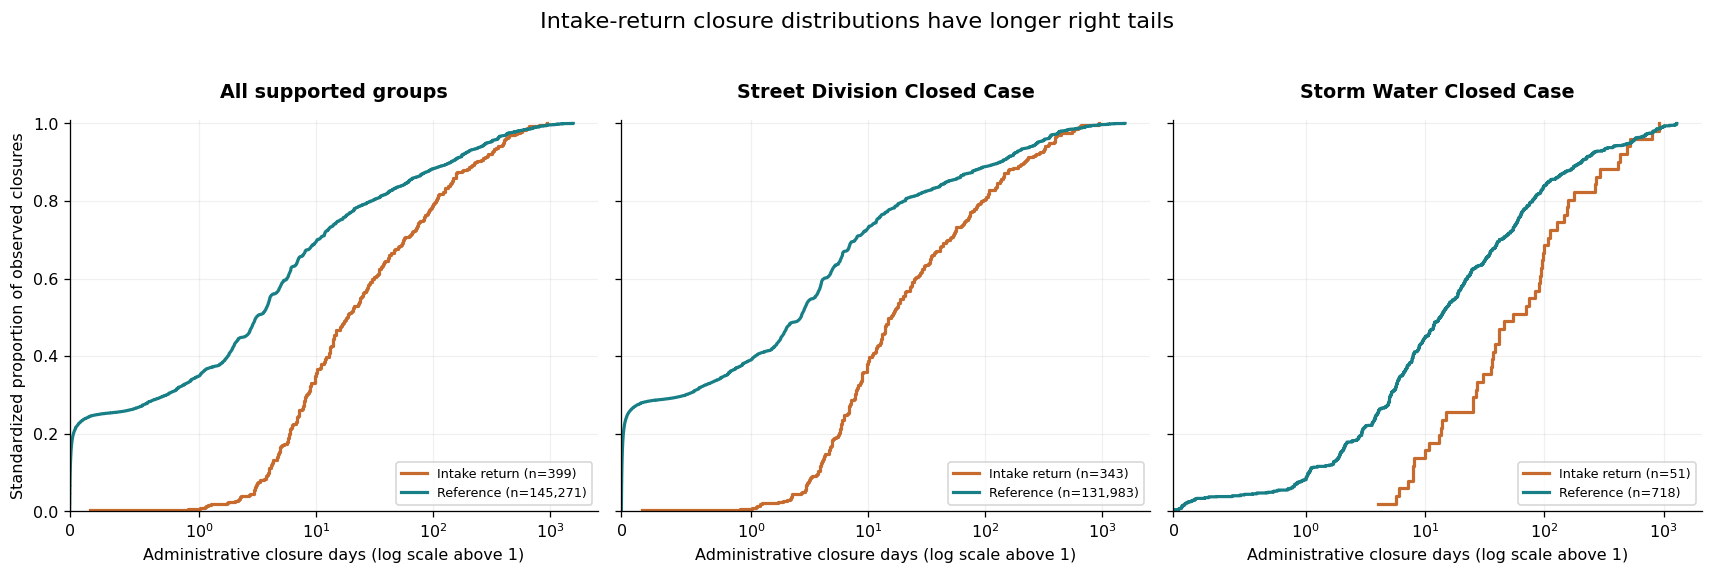

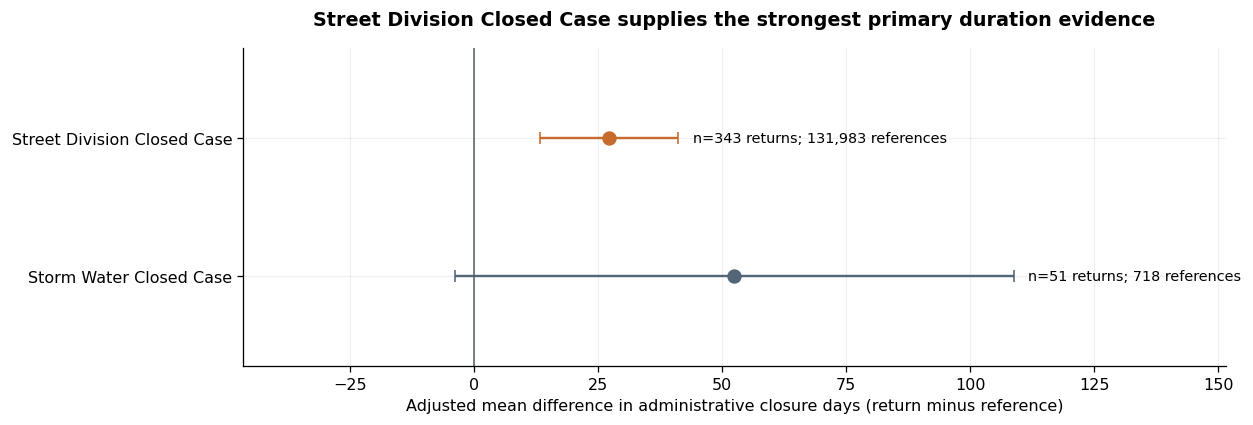

In [13]:
plot_groups=['All supported groups','Street Division Closed Case','Storm Water Closed Case']
fig,axes=plt.subplots(1,3,figsize=(15,4.8),sharey=True)
for ax,group in zip(axes,plot_groups):
    z=weighted_closed if group=='All supported groups' else weighted_closed.loc[weighted_closed.service_group.eq(group)]
    for arm,label,color in [(True,'Intake return',RETURN),(False,'Reference',REFERENCE)]:
        q=z.loc[z.return_to_intake.eq(arm)].sort_values('duration_days')
        if q.empty:continue
        cumulative=q.weight.cumsum()/q.weight.sum()
        ax.step(q.duration_days,cumulative,where='post',color=color,label=f'{label} (n={len(q):,})',lw=2)
    ax.set_xscale('symlog',linthresh=1);ax.set_xlim(left=0);ax.set_ylim(0,1.01)
    ax.set_title(textwrap.fill(group,29));ax.set_xlabel('Administrative closure days (log scale above 1)')
    ax.legend(loc='lower right',fontsize=8);ax.set_yticks(np.arange(0,1.01,.2))
axes[0].set_ylabel('Standardized proportion of observed closures')
fig.suptitle('Intake-return closure distributions have longer right tails',fontsize=14,y=1.03)
fig.tight_layout();plt.show()

fg=differences.loc[differences.service_group.ne('All supported groups')&differences.return_closed_n.ge(50)].copy()
fg=fg.sort_values('return_closed_n',ascending=True)
fig,ax=plt.subplots(figsize=(11,3.8))
for i,(_,r) in enumerate(fg.iterrows()):
    ax.errorbar(r.adjusted_mean_diff,i,xerr=[[r.adjusted_mean_diff-r.ci_low],[r.ci_high-r.adjusted_mean_diff]],
                fmt='o',color=RETURN if r.substantial_sample else NEUTRAL,capsize=4,ms=8)
    ax.text(r.ci_high+3,i,f'n={int(r.return_closed_n)} returns; {int(r.reference_closed_n):,} references',va='center',fontsize=9)
ax.axvline(0,color='#58616A',lw=1);ax.set_yticks(range(len(fg)),fg.service_group)
ax.set_xlabel('Adjusted mean difference in administrative closure days (return minus reference)')
ax.set_title('Street Division Closed Case supplies the strongest primary duration evidence')
ax.set_ylim(-.65,len(fg)-.35);ax.margins(x=.38);fig.tight_layout();plt.show()

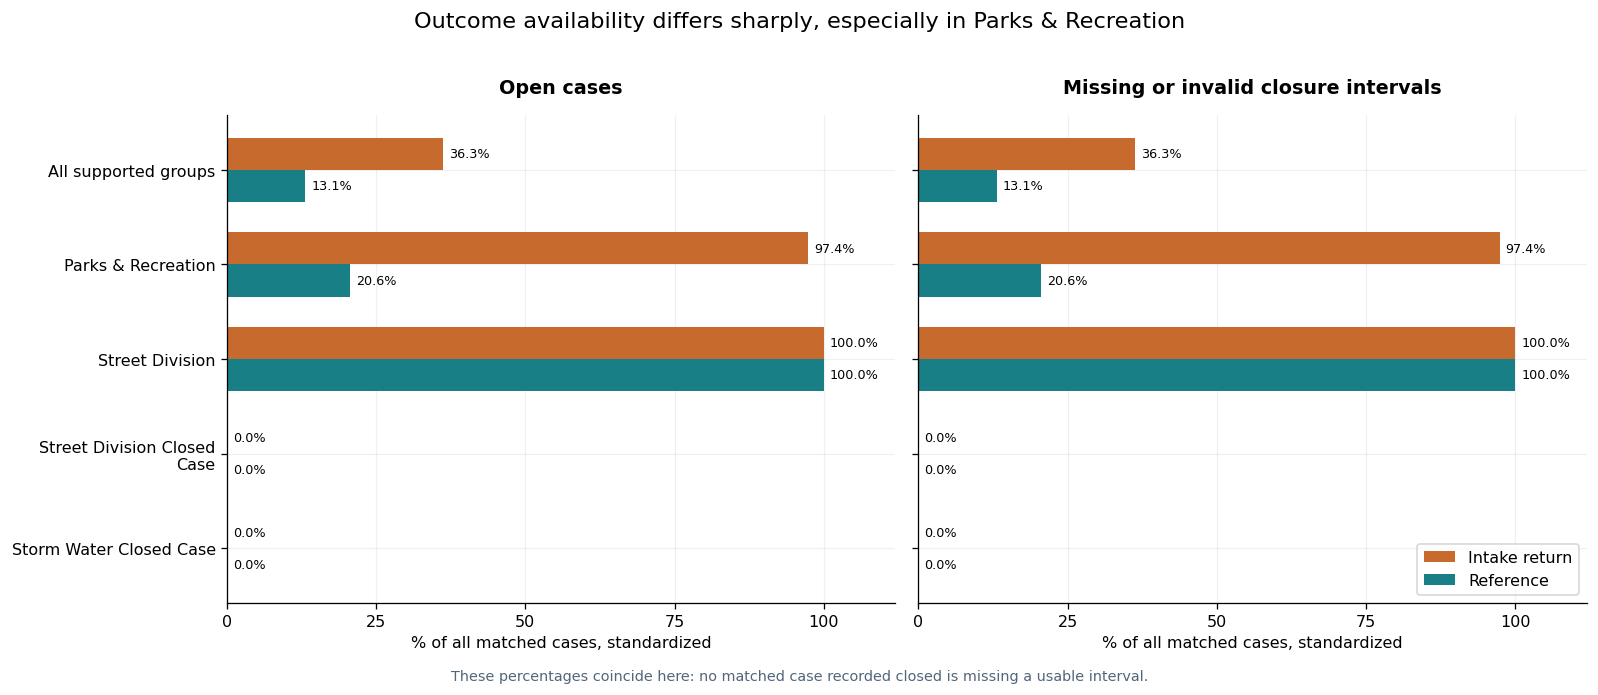

In [14]:
groups=['All supported groups','Parks & Recreation','Street Division','Street Division Closed Case','Storm Water Closed Case']
fig,axes=plt.subplots(1,2,figsize=(14,5.6),sharey=True)
y=np.arange(len(groups));h=.34
for ax,metric,title in [(axes[0],'adjusted_open_pct','Open cases'),
                        (axes[1],'adjusted_no_usable_date_pct','Missing or invalid closure intervals')]:
    for arm,label,color,offset in [('Intake return','Intake return',RETURN,-h/2),('Reference','Reference',REFERENCE,h/2)]:
        vals=rates.loc[rates.arm.eq(arm)].set_index('service_group').reindex(groups)[metric]
        ax.barh(y+offset,vals,height=h,color=color,label=label)
        for yi,v in zip(y+offset,vals):ax.text(min(v+1,101),yi,f'{v:.1f}%',va='center',fontsize=8)
    ax.set_xlim(0,112);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('% of all matched cases, standardized');ax.set_title(title)
axes[0].set_yticks(y,[textwrap.fill(g,26) for g in groups]);axes[0].invert_yaxis();axes[1].legend(loc='lower right')
fig.suptitle('Outcome availability differs sharply, especially in Parks & Recreation',fontsize=14,y=1.02)
fig.text(.5,-.02,'These percentages coincide here: no matched case recorded closed is missing a usable interval.',
         ha='center',fontsize=9,color=NEUTRAL)
fig.tight_layout();plt.show()

## 5. Closure dispositions and administrative pathways

The next tables separate types of closure rather than interpreting every closed record as repaired. Disposition summaries include **all matched cases**, so missing closure outcomes remain visible. Within each tag, the raw distributions can still differ in baseline case mix. The later exact-disposition sensitivity re-matches the original covariates plus this text-derived tag; it changes the target sample and can condition on a consequence of the workflow. It is a diagnostic of how much the primary association depends on disposition composition, not a preferred causal estimate.

**Matched sample by text-derived disposition and exposure (False = reference)**

,disposition,return_to_intake,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days
0,Duplicate or linked report,False,"1,164",56.44,56.44,56.44,0,507,23.19,216.50,765.52
1,Duplicate or linked report,True,29,24.14,24.14,24.14,0,22,17.94,68.95,147.31
2,Future work or partial repair,False,638,1.10,1.10,1.10,0,631,1.69,38.27,98.27
3,Future work or partial repair,True,15,0.00,0.00,0.00,0,15,9.89,50.64,133.48
4,No action or jurisdiction limitation,False,"2,789",0.11,0.11,0.11,0,"2,786",1.91,76.23,273.73
5,No action or jurisdiction limitation,True,40,0.00,0.00,0.00,0,40,22.57,100.82,307.95
6,No action text,False,"10,070",25.54,25.54,25.54,0,"7,498",10.95,83.92,275.16
7,No action text,True,259,77.99,77.99,77.99,0,57,65.72,119.50,397.82
8,Other action text,False,"10,465",0.01,0.01,0.01,0,"10,464",3.78,22.15,51.96
9,Other action text,True,4,0.00,0.00,0.00,0,4,387.32,429.16,691.37


**Recorded statuses among administratively closed matched cases**

return_to_intake,status,reference_cases,return_cases
0,Closed,"113,111",391
1,Closed - Referred,"48,898",13
2,Cancelled,12,0


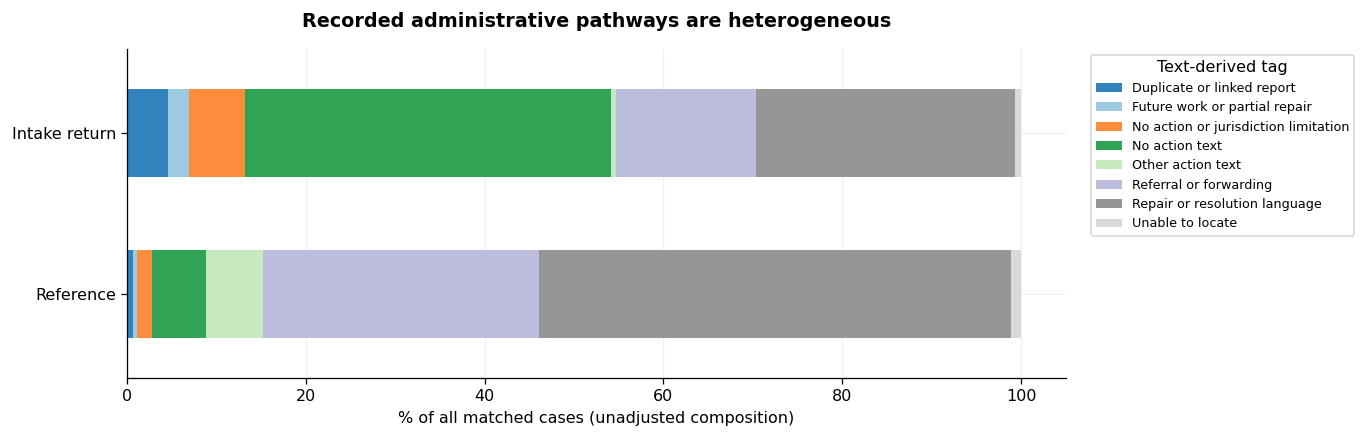

In [15]:
disposition_summary=m.groupby(['disposition','return_to_intake'],observed=True).apply(raw_summary).reset_index()
table(disposition_summary,'Matched sample by text-derived disposition and exposure (False = reference)')
closed_status=pd.crosstab(m.loc[m.closed,'status'],m.loc[m.closed,'return_to_intake'])
table(closed_status.rename(columns={False:'reference_cases',True:'return_cases'}).reset_index(),
      'Recorded statuses among administratively closed matched cases')
disp_counts=m.groupby(['return_to_intake','disposition'],observed=True).size().unstack(fill_value=0)
fig,ax=plt.subplots(figsize=(12,3.9))
disp_pct=disp_counts.div(disp_counts.sum(axis=1),axis=0)*100
disp_pct.index=['Reference' if not k else 'Intake return' for k in disp_pct.index]
disp_pct.plot.barh(stacked=True,ax=ax,colormap='tab20c',width=.55)
ax.set_xlabel('% of all matched cases (unadjusted composition)');ax.set_ylabel('')
ax.set_title('Recorded administrative pathways are heterogeneous')
ax.legend(title='Text-derived tag',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
fig.tight_layout();plt.show()

## 6. Cohort follow-up and why no censored-time model is fitted

Creation-year matching reduces broad calendar imbalance but cannot make a January case comparable in follow-up to an October case in the same year. Creation-quarter matching and older-cohort restrictions below test this concern.

Neither the file modification timestamp nor the maximum `Last Modified Date`/`SystemModstamp` proves that every case was observed through one common export date. As a diagnostic only, add the stored `Days Old` value to the normalized creation date for currently open cases. Multiple dominant implied dates would indicate differing formula refreshes or extracts. The formula definition and refresh behavior are not supplied. `Total Days Open` is also inspected and never substituted for an observed closure interval.

The observed span between creation and a case’s own last modification is a **lower bound on the age of that record at extraction**, not time spent continuously open, time at intake, or a censoring time. Without a documented observation window and status history, no Kaplan–Meier curve, hazard ratio, or extrapolated lifetime is reported. Old open cases establish unresolved administrative outcomes in the extract; their eventual closure durations remain unidentified.

**Implied age-field refresh dates; diagnostic, not certified follow-up**

,stored age field,implied calendar date,open_cases,pct_of_open_with_field
0,Days Old,2026-10-14,"252,804",95.56
1,Days Old,2026-10-26,"11,744",4.44
2,Total Days Open,2026-10-14,"107,850",98.08
3,Total Days Open,2026-10-26,"2,106",1.92


**Matched cases by creation year and exposure; no closure imputation**

,creation_year,return_to_intake,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days
0,"2,022.00",False,"41,512",0.17,0.17,0.17,0,"41,443",4.12,47.42,176.69
1,"2,022.00",True,88,5.68,5.68,5.68,0,83,25.27,85.99,257.71
2,"2,023.00",False,"54,264",0.88,0.88,0.88,0,"53,785",3.04,21.97,28.09
3,"2,023.00",True,253,11.46,11.46,11.46,0,224,14.42,83.54,284.45
4,"2,024.00",False,"35,446",1.93,1.93,1.93,0,"34,761",0.87,14.09,19.54
5,"2,024.00",True,79,26.58,26.58,26.58,0,58,24.17,70.29,212.15
6,"2,025.00",False,"17,351",0.39,0.39,0.39,0,"17,283",2.09,12.40,25.85
7,"2,025.00",True,42,30.95,30.95,30.95,0,29,10.98,30.68,62.98
8,"2,026.00",False,"16,901",12.73,12.73,12.73,0,"14,749",6.14,16.61,41.80
9,"2,026.00",True,172,94.19,94.19,94.19,0,10,42.99,51.32,93.06


**Currently open cases: creation-to-last-modification spans, not completed lifetimes**

,arm,open_cases,median_record_span_days,p90_record_span_days
0,Intake return,427,113.67,932.44
1,All non-return,"264,121",175.23,"1,957.95"


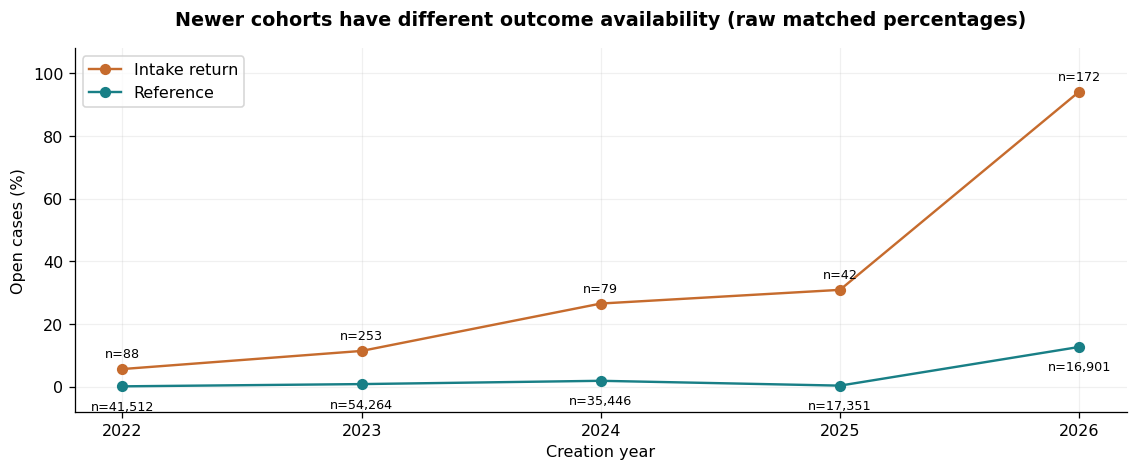

In [16]:
age_diagnostics=[]
for c in ['Days Old','Total Days Open']:
    z=d.loc[a.open,['Created Date',c]].dropna()
    implied=z['Created Date'].dt.normalize()+pd.to_timedelta(z[c].astype('float64'),unit='D')
    vc=implied.value_counts().head(5)
    for date,n in vc.items():age_diagnostics.append({'stored age field':c,'implied calendar date':date.date(),
        'open_cases':int(n),'pct_of_open_with_field':100*n/len(z)})
table(pd.DataFrame(age_diagnostics),'Implied age-field refresh dates; diagnostic, not certified follow-up')
cohort=m.groupby(['creation_year','return_to_intake'],observed=True).apply(raw_summary).reset_index()
table(cohort,'Matched cases by creation year and exposure; no closure imputation')
span=(d['Last Modified Date']-d['Created Date']).dt.total_seconds()/86400
open_span=pd.DataFrame([{'arm':label,'open_cases':int((a.open&a.return_to_intake.eq(arm)).sum()),
    'median_record_span_days':span.loc[a.open&a.return_to_intake.eq(arm)].median(),
    'p90_record_span_days':span.loc[a.open&a.return_to_intake.eq(arm)].quantile(.9)}
    for arm,label in [(True,'Intake return'),(False,'All non-return')]])
table(open_span,'Currently open cases: creation-to-last-modification spans, not completed lifetimes')
year_plot=cohort.pivot(index='creation_year',columns='return_to_intake',values='open_pct')
fig,ax=plt.subplots(figsize=(10,4.2))
for arm,label,color in [(True,'Intake return',RETURN),(False,'Reference',REFERENCE)]:
    ax.plot(year_plot.index,year_plot[arm],marker='o',color=color,label=label)
    for year,v in year_plot[arm].items():
        n=int(cohort.loc[cohort.creation_year.eq(year)&cohort.return_to_intake.eq(arm),'cases'].iloc[0])
        ax.annotate(f'n={n:,}',(year,v),xytext=(0,7 if arm else -15),textcoords='offset points',ha='center',fontsize=8)
ax.set_xlabel('Creation year');ax.set_ylabel('Open cases (%)');ax.set_ylim(-8,108)
ax.set_xticks(year_plot.index.astype(int))
ax.set_title('Newer cohorts have different outcome availability (raw matched percentages)');ax.legend()
fig.tight_layout();plt.show()

## 7. Sensitivity analyses

Rebuild support and weights for each specification. Report its retained sample; differences across rows can reflect changed populations as well as changed reference definitions. The no-referral definition excludes referral metadata from **references only** and is deliberately a different comparator. The no-parent definition excludes linked cases in **both** arms. The complete-covariate definition requires an actual report category, priority, and channel. Quarter matching adds creation quarter within year; a first-half-of-year restriction and a through-2024 cohort reduce unequal follow-up without inventing a common censoring date. The family definition is a sensitivity, since merging recorded groups changes the question.

**All sensitivities: outcome availability and conditional closure-time differences**

,specification,matched_return_n,matched_reference_n,time_return_n,time_reference_n,return_open_pct,reference_open_pct,adjusted_mean_diff_days,ci_low,ci_high
0,Primary,634,"165,474",399,"145,271",36.28,13.14,30.09,16.15,44.02
1,Include Other Department,634,"165,475",399,"145,271",36.28,13.14,30.09,16.15,44.02
2,Known reasons only,616,"129,892",394,"112,340",35.23,6.26,31.62,17.39,45.85
3,References without referral metadata,621,"115,798",386,"98,288",37.04,14.20,12.08,-2.42,26.58
4,Relaxed overlap: 1 return / 10 references,877,"333,394",437,"160,061",41.73,14.94,29.73,13.40,46.05
5,Case Type only as category,640,"193,878",405,"173,673",35.94,13.02,29.29,15.41,43.18
6,Complete recorded covariates,634,"165,474",399,"145,271",36.28,13.14,30.09,16.15,44.02
7,Unlinked cases in both arms,547,"135,631",357,"123,815",34.37,12.55,33.57,18.87,48.27
8,Combine literal Closed Case suffix,665,"176,480",405,"145,536",38.20,8.75,33.86,17.40,50.31
9,Created through 2024,420,"131,222",363,"119,414",13.10,8.99,30.74,15.49,45.99


**Sensitivity detail: all-case denominators, open/missing outcomes, raw closure summaries, and adjusted availability**

,specification,arm,cases,open_pct,no_usable_date_pct,outcome_unavailable_pct,closed_missing_date_n,usable_closures,median_days,mean_days,p90_days,adjusted_open_pct,adjusted_no_usable_date_pct,adjusted_outcome_unavailable_pct,adjusted_closed_missing_date_pct,effective_n
0,Primary,Intake return,634,36.28,36.28,36.28,0,404,18.41,77.55,226.30,36.28,36.28,36.28,0.00,634.00
1,Primary,Reference,"165,474",2.09,2.09,2.09,0,"162,021",2.87,25.28,46.29,13.14,13.14,13.14,0.00,"7,062.12"
2,Include Other Department,Intake return,634,36.28,36.28,36.28,0,404,18.41,77.55,226.30,36.28,36.28,36.28,0.00,634.00
3,Include Other Department,Reference,"165,475",2.09,2.09,2.09,0,"162,021",2.87,25.28,46.29,13.14,13.14,13.14,0.00,"7,062.15"
4,Known reasons only,Intake return,616,35.23,35.23,35.23,0,399,18.70,78.35,228.46,35.23,35.23,35.23,0.00,616.00
5,Known reasons only,Reference,"129,892",0.68,0.68,0.68,0,"129,004",2.52,24.93,44.03,6.26,6.26,6.26,0.00,"6,117.85"
6,References without referral metadata,Intake return,621,37.04,37.04,37.04,0,391,17.93,76.71,226.89,37.04,37.04,37.04,0.00,621.00
7,References without referral metadata,Reference,"115,798",2.86,2.86,2.86,0,"112,490",4.93,34.83,84.59,14.20,14.20,14.20,0.00,"6,260.92"
8,Relaxed overlap: 1 return / 10 references,Intake return,877,41.73,41.73,41.73,0,511,24.67,91.24,267.78,41.73,41.73,41.73,0.00,877.00
9,Relaxed overlap: 1 return / 10 references,Reference,"333,394",3.56,3.56,3.56,0,"321,512",3.93,37.50,92.00,14.94,14.94,14.94,0.00,"11,075.32"


**Sensitivity detail: raw and adjusted mean, median, and 90th percentile on each time-supported sample**

,specification,arm,closed_n,time_target_all_cases,unadjusted_mean_days,unadjusted_median_days,unadjusted_p90_days,adjusted_mean_days,adjusted_median_days,adjusted_p90_days,effective_closed_n
0,Primary,Intake return,399,399,77.90,18.14,228.46,77.90,18.14,231.60,399.00
1,Primary,Reference,"145,271","145,280",24.20,2.63,37.21,47.81,3.06,142.23,"3,443.13"
2,Include Other Department,Intake return,399,399,77.90,18.14,228.46,77.90,18.14,231.60,399.00
3,Include Other Department,Reference,"145,271","145,280",24.20,2.63,37.21,47.81,3.06,142.23,"3,443.13"
4,Known reasons only,Intake return,394,394,78.71,18.69,232.39,78.71,18.69,236.98,394.00
5,Known reasons only,Reference,"112,340","112,343",23.50,1.91,32.23,47.08,2.85,139.91,"3,060.39"
6,References without referral metadata,Intake return,386,386,77.06,17.78,230.82,77.06,17.78,233.96,386.00
7,References without referral metadata,Reference,"98,288","98,296",34.43,4.58,84.35,64.98,5.66,194.88,"2,974.20"
8,Relaxed overlap: 1 return / 10 references,Intake return,437,437,89.60,20.85,270.08,89.60,20.85,272.39,437.00
9,Relaxed overlap: 1 return / 10 references,Reference,"160,061","160,070",28.59,2.45,54.93,59.88,3.71,173.85,"3,815.49"


**Service-group sensitivity results, including sample sizes and intervals**

,specification,service_group,time_strata,return_closed_n,reference_closed_n,time_target_return_n,unadjusted_mean_diff,adjusted_mean_diff,ci_low,ci_high,adjusted_median_diff,adjusted_p90_diff,p_value,substantial_sample,fdr_q
1,Primary,Storm Water Closed Case,5,51,718,51,55.31,52.45,-3.80,108.71,41.48,219.31,0.07,False,—
2,Primary,Street Division Closed Case,13,343,"131,983",343,45.31,27.14,13.26,41.03,13.15,84.78,0.00,True,0.00
4,Include Other Department,Storm Water Closed Case,5,51,718,51,55.31,52.45,-3.80,108.71,41.48,219.31,0.07,False,—
5,Include Other Department,Street Division Closed Case,13,343,"131,983",343,45.31,27.14,13.26,41.03,13.15,84.78,0.00,True,0.00
7,Known reasons only,Storm Water Closed Case,4,46,538,46,69.02,65.16,1.39,128.93,69.79,229.52,0.05,False,—
8,Known reasons only,Street Division Closed Case,13,343,"99,232",343,45.65,27.53,13.59,41.46,13.43,85.55,0.00,True,0.00
10,References without referral metadata,Storm Water Closed Case,5,51,662,51,50.22,46.58,-10.02,103.17,39.37,207.56,0.11,False,—
11,References without referral metadata,Street Division Closed Case,12,330,"86,040",330,32.01,6.88,-7.65,21.40,9.99,19.76,0.35,True,0.35
13,Relaxed overlap: 1 return / 10 references,Storm Water Closed Case,9,66,970,66,67.65,26.62,-38.07,91.31,46.21,-10.59,0.42,False,—
14,Relaxed overlap: 1 return / 10 references,Street Division Closed Case,19,362,"146,091",362,45.71,27.91,12.65,43.16,14.01,72.41,0.00,True,0.00


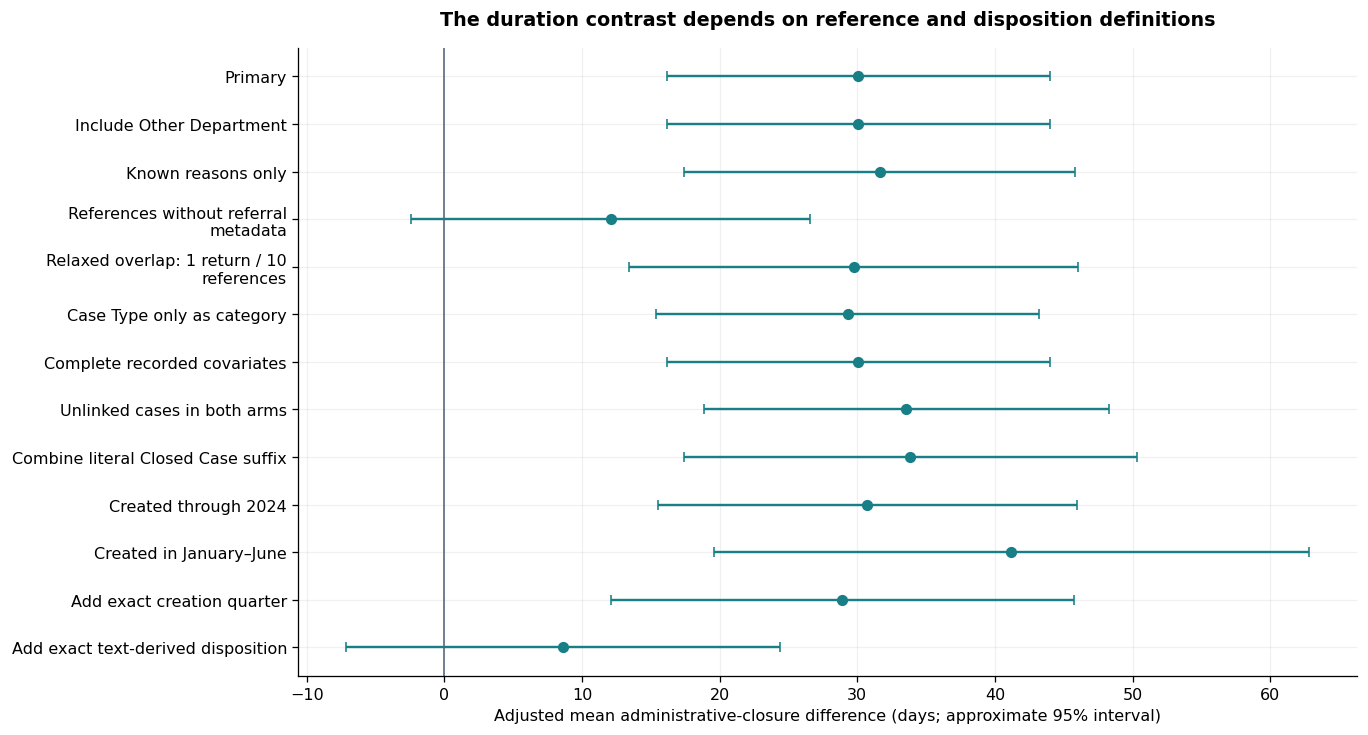

8884

In [17]:
a['creation_quarter']=a.created.dt.quarter.astype('int8')
complete=a.report_category.ne(MISSING)&a.priority.ne(MISSING)&a.channel.ne(MISSING)
settings=[('Primary',{}),('Include Other Department',{'reference':'all_non_return'}),
    ('Known reasons only',{'reference':'known_reason'}),('References without referral metadata',{'reference':'no_referral'}),
    ('Relaxed overlap: 1 return / 10 references',{'min_return':1,'min_control':10}),
    ('Case Type only as category',{'case_type_only':d['Case Type']}),
    ('Complete recorded covariates',{'eligible':complete}),('Unlinked cases in both arms',{'eligible':~a.has_parent}),
    ('Combine literal Closed Case suffix',{'service_family':True}),
    ('Created through 2024',{'eligible':a.creation_year.le(2024)}),
    ('Created in January–June',{'eligible':a.created.dt.month.le(6)}),
    ('Add exact creation quarter',{'extra_keys':['creation_quarter']}),
    ('Add exact text-derived disposition',{'extra_keys':['disposition']})]
sensitivity_rows=[];sensitivity_groups=[];sensitivity_availability=[];sensitivity_distributions=[]
for name,kwargs in settings:
    if name=='Primary':sm,ss,sf,sr,st,sd=m,support,flow,rates,times,differences
    else:
        sm,ss,sf=match_cases(a,**kwargs)
        sr,st,sd,_=compare_matched(sm)
    rr=sr.loc[sr.service_group.eq('All supported groups')].set_index('arm')
    dd=sd.loc[sd.service_group.eq('All supported groups')].iloc[0] if len(sd) else pd.Series(dtype=float)
    sensitivity_rows.append({'specification':name,'matched_return_n':int(sm.return_to_intake.sum()),
        'matched_reference_n':int((~sm.return_to_intake).sum()),'time_return_n':dd.get('return_closed_n',np.nan),
        'time_reference_n':dd.get('reference_closed_n',np.nan),
        'return_open_pct':rr.loc['Intake return','adjusted_open_pct'],
        'reference_open_pct':rr.loc['Reference','adjusted_open_pct'],
        'adjusted_mean_diff_days':dd.get('adjusted_mean_diff',np.nan),
        'ci_low':dd.get('ci_low',np.nan),'ci_high':dd.get('ci_high',np.nan)})
    for _,row in sd.loc[sd.service_group.ne('All supported groups')].iterrows():
        sensitivity_groups.append({'specification':name,**row.to_dict()})
    for _,row in sr.loc[sr.service_group.eq('All supported groups')].iterrows():
        sensitivity_availability.append({'specification':name,**row.to_dict()})
    for _,row in st.loc[st.service_group.eq('All supported groups')].iterrows():
        sensitivity_distributions.append({'specification':name,**row.to_dict()})
sensitivity=pd.DataFrame(sensitivity_rows);sensitivity_group_results=pd.DataFrame(sensitivity_groups)
table(sensitivity,'All sensitivities: outcome availability and conditional closure-time differences')
table(pd.DataFrame(sensitivity_availability).drop(columns=['service_group']),
    'Sensitivity detail: all-case denominators, open/missing outcomes, raw closure summaries, and adjusted availability')
table(pd.DataFrame(sensitivity_distributions).drop(columns=['service_group']),
    'Sensitivity detail: raw and adjusted mean, median, and 90th percentile on each time-supported sample')
table(sensitivity_group_results.loc[sensitivity_group_results.service_group.isin(
    ['Street Division Closed Case','Storm Water Closed Case','Street Division','Storm Water'])],
    'Service-group sensitivity results, including sample sizes and intervals')
fig,ax=plt.subplots(figsize=(12,6.5))
sp=sensitivity.iloc[::-1]
ax.errorbar(sp.adjusted_mean_diff_days,np.arange(len(sp)),
    xerr=np.vstack([sp.adjusted_mean_diff_days-sp.ci_low,sp.ci_high-sp.adjusted_mean_diff_days]),
    fmt='o',color=REFERENCE,capsize=3)
ax.axvline(0,color=NEUTRAL,lw=1);ax.set_yticks(range(len(sp)),[textwrap.fill(s,35) for s in sp.specification])
ax.set_xlabel('Adjusted mean administrative-closure difference (days; approximate 95% interval)')
ax.set_title('The duration contrast depends on reference and disposition definitions')
fig.tight_layout();plt.show()
del sm,ss,sf,sr,st,sd
gc.collect()

## 8. Report categories associated with returns and candidate review areas

Category frequencies are exploratory, not estimates of incorrect routing. The primary-reference population plus returns supplies denominators. A service-group-standardized enrichment measure divides observed category returns by expected returns under each recorded group’s overall return rate: \(E_k=\sum_g N_{gk}(N_{Tg}/N_g)\). Values above one mean more returns than expected from group composition alone; they do not adjust for priority, channel, year, or case complexity. Require at least 10 returns and 200 total cases before displaying enrichment. Do not promote a tiny category because of a large ratio.

Review candidates require at least 20 returns in a group/category and are ordered by return volume. The chart and table are a practical sampling agenda: they do not monetize excess days, estimate intake handling time, or label any case a misroute.

**Categories with substantial intake-return counts; association only**

,report_category,cases,return_cases,expected_returns,return_pct,group_standardized_enrichment
0,Case Type: Other,"96,588",481,134.01,0.50,3.59
1,Case Type: Graffiti,"169,215",239,144.98,0.14,1.65
2,Case Type: Illegal Dumping,"481,603",70,32.21,0.01,2.17
3,Case Type: Brush Management/Weeds,617,29,3.19,4.70,9.10
4,Case Type: Sprinkler/Irrigation,"2,772",27,15.22,0.97,1.77
5,Case Type: Potential Tree Hazard,"1,066",26,5.45,2.44,4.77
6,Case Type: Tree hazard/Brush management,848,20,4.51,2.36,4.44
7,Case Type: Fencing,356,16,1.92,4.49,8.35
8,Case Type: Park Lighting Issue,475,14,2.43,2.95,5.76
9,Case Type: Trash/Litter,"1,574",13,8.70,0.83,1.49


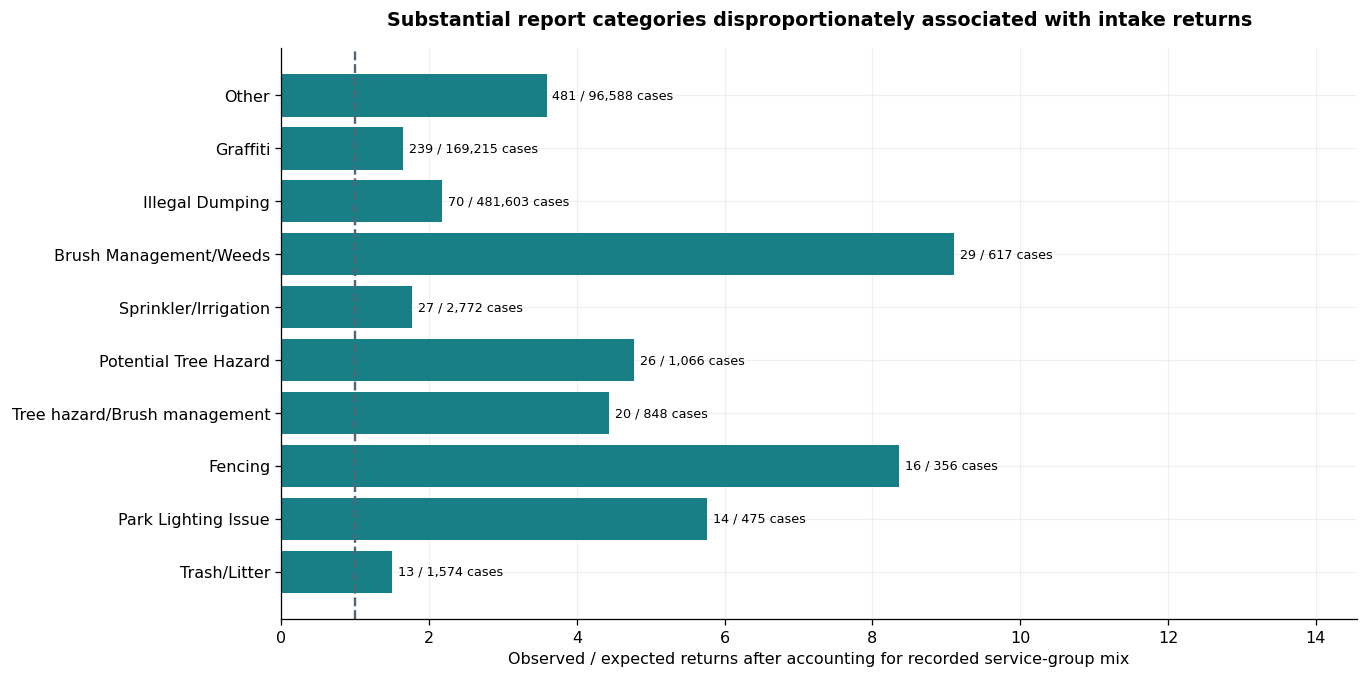

**Highest-volume service-group/category candidates for City staff review**

,service_group,report_category,cases,return_cases,expected_returns,open_pct,usable_closures,mean_days,median_days,p90_days,return_pct,staff_review_focus
0,Street Division Closed Case,Case Type: Other,"57,012",254,22.30,0.00,254,110.43,31.11,328.90,0.45,Review closure dispositions and dated assignment/return events
1,Street Division Closed Case,Case Type: Graffiti,"122,663",147,47.97,0.00,147,30.35,10.74,55.03,0.12,Review closure dispositions and dated assignment/return events
2,Parks & Recreation,Case Type: Other,"18,496",103,102.79,96.12,4,60.73,35.07,129.54,0.56,"Check open backlog, handoff acceptance, and whether the reason is cleared"
3,Storm Water Closed Case,Case Type: Other,"1,102",60,3.68,0.00,60,178.27,91.59,499.25,5.44,Review closure dispositions and dated assignment/return events
4,Street Division,Case Type: Other,"2,094",42,3.50,100.00,0,—,—,—,2.01,Trace current ownership and links to receiving-system records
5,Parks & Recreation,Case Type: Graffiti,"15,593",41,86.66,85.37,6,19.60,11.57,42.78,0.26,"Check open backlog, handoff acceptance, and whether the reason is cleared"
6,Parks & Recreation,Case Type: Illegal Dumping,"4,335",29,24.09,100.00,0,—,—,—,0.67,"Check open backlog, handoff acceptance, and whether the reason is cleared"
7,Parks & Recreation,Case Type: Sprinkler/Irrigation,"2,737",27,15.21,100.00,0,—,—,—,0.99,"Check open backlog, handoff acceptance, and whether the reason is cleared"
8,Street Division,Case Type: Graffiti,"1,777",26,2.97,100.00,0,—,—,—,1.46,Trace current ownership and links to receiving-system records
9,Parks & Recreation,Case Type: Brush Management/Weeds,568,22,3.16,100.00,0,—,—,—,3.87,"Check open backlog, handoff acceptance, and whether the reason is cleared"


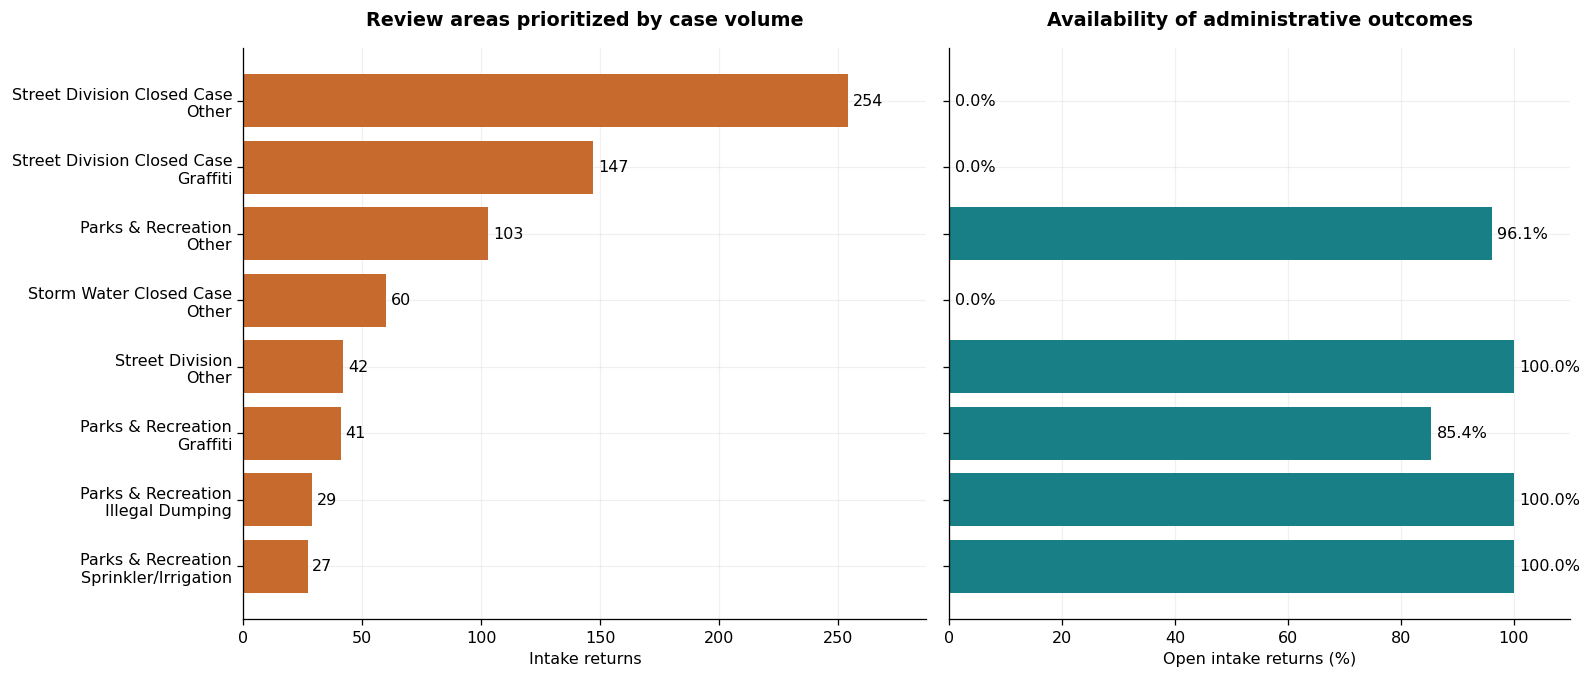

In [18]:
pop=a.loc[a.return_to_intake|~a.other_department]
gc_counts=pop.groupby(['service_group','report_category'],observed=True).agg(
    cases=('return_to_intake','size'),return_cases=('return_to_intake','sum'))
gr=pop.groupby('service_group',observed=True).return_to_intake.mean()
gc_counts['expected_returns']=gc_counts.cases*gc_counts.index.get_level_values('service_group').map(gr).to_numpy()
category=gc_counts.groupby('report_category',observed=True)[['cases','return_cases','expected_returns']].sum()
category['return_pct']=100*category.return_cases/category.cases
category['group_standardized_enrichment']=category.return_cases/category.expected_returns.replace(0,np.nan)
category=category.sort_values('return_cases',ascending=False)
category_display=category.loc[category.return_cases.ge(10)&category.cases.ge(200)]
table(category_display.reset_index(),'Categories with substantial intake-return counts; association only')
cp=category_display.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(12,6))
ax.barh(np.arange(len(cp)),cp.group_standardized_enrichment,color=REFERENCE)
ax.set_yticks(range(len(cp)),[textwrap.fill(str(s).replace('Case Type: ',''),36) for s in cp.index])
for i,(_,r) in enumerate(cp.iterrows()):ax.text(r.group_standardized_enrichment+.08,i,f'{int(r.return_cases)} / {int(r.cases):,} cases',va='center',fontsize=8)
ax.axvline(1,color=NEUTRAL,ls='--');ax.set_xlim(0,cp.group_standardized_enrichment.max()*1.6)
ax.set_xlabel('Observed / expected returns after accounting for recorded service-group mix')
ax.set_title('Substantial report categories disproportionately associated with intake returns')
fig.tight_layout();plt.show()

return_by_area=a.loc[a.return_to_intake].groupby(['service_group','report_category'],observed=True).apply(raw_summary)
candidates=gc_counts.loc[gc_counts.return_cases.ge(20)].join(
    return_by_area[['open_pct','usable_closures','mean_days','median_days','p90_days']]).sort_values('return_cases',ascending=False)
candidates['return_pct']=100*candidates.return_cases/candidates.cases
candidates=candidates.reset_index()
candidates['staff_review_focus']=np.where(candidates.service_group.eq('Parks & Recreation'),
    'Check open backlog, handoff acceptance, and whether the reason is cleared',
    np.where(candidates.service_group.str.contains('Closed Case'),
    'Review closure dispositions and dated assignment/return events',
    'Trace current ownership and links to receiving-system records'))
table(candidates,'Highest-volume service-group/category candidates for City staff review')
cv=candidates.head(8).iloc[::-1]
fig,axes=plt.subplots(1,2,figsize=(14,6),gridspec_kw={'width_ratios':[1.1,1]})
labels=[textwrap.fill(r.service_group,32)+'\n'+textwrap.fill(r.report_category.replace('Case Type: ',''),32) for _,r in cv.iterrows()]
y=np.arange(len(cv));axes[0].barh(y,cv.return_cases,color=RETURN);axes[0].set_yticks(y,labels)
axes[1].barh(y,cv.open_pct,color=REFERENCE);axes[1].set_yticks(y,[]);axes[1].set_xlim(0,110)
for i,(_,r) in enumerate(cv.iterrows()):
    axes[0].text(r.return_cases+2,i,f'{int(r.return_cases)}',va='center')
    axes[1].text(min(r.open_pct+1,101),i,f'{r.open_pct:.1f}%',va='center')
axes[0].set_xlabel('Intake returns');axes[1].set_xlabel('Open intake returns (%)')
axes[0].set_title('Review areas prioritized by case volume');axes[1].set_title('Availability of administrative outcomes')
axes[0].set_xlim(0,cv.return_cases.max()*1.13);fig.tight_layout();plt.show()

## 9. Reconciliation and result validation

In [19]:
# Reconcile source counts and independently reconstruct the main standardized contrast.
assert len(d)==load_audit['raw_rows']-len(drop_index)
assert d.loc[d['Case ID'].notna(),'Case ID'].is_unique
assert int(a.return_to_intake.sum())==len(intake_cases)
assert not a.loc[a.return_to_intake,'other_department'].any()
assert a.duration_days.dropna().ge(0).all()
assert len(a)==int(a.return_to_intake.sum())+int((~a.return_to_intake).sum())
assert np.allclose(flow.eligible_return,flow.matched_return+flow.unmatched_return)
assert np.allclose(flow.eligible_control,flow.matched_control+flow.unmatched_control)
assert int(flow.matched_return.sum())==int(m.return_to_intake.sum())
assert not m.loc[~m.return_to_intake,'other_department'].any()
assert support.return_n.ge(5).all() and support.control_n.ge(20).all()
assert not support.duplicated(KEYS).any()
assert balance.max_absolute_weighted_share_gap.max()<1e-10
assert np.isclose(weighted_closed.loc[weighted_closed.return_to_intake,'weight'].sum(),time_target_return_n)
assert np.isclose(weighted_closed.loc[~weighted_closed.return_to_intake,'weight'].sum(),time_target_return_n)
assert a.disposition.notna().all()
assert int(disposition_summary.cases.sum())==len(m)
independent=weighted_closed.groupby(['stratum','return_to_intake'],observed=True).duration_days.mean().unstack()
target_by_stratum=m.loc[m.return_to_intake&m.stratum.isin(independent.index)].groupby('stratum').size()
independent_delta=np.average(independent[True]-independent[False],weights=target_by_stratum.reindex(independent.index))
headline=differences.loc[differences.service_group.eq('All supported groups')].iloc[0]
assert np.isclose(independent_delta,headline.adjusted_mean_diff)
assert times.loc[times.arm.eq('Intake return'),'adjusted_p90_days'].ge(
    times.loc[times.arm.eq('Intake return'),'adjusted_median_days']).all()
assert source_rows==4_312_496, 'This source differs from the analyzed capstone extract; review all findings.'
assert len(intake_cases)==1_033, 'Intake label count changed; review all findings.'
validation=pd.DataFrame({'check':['Source and deduplication reconcile','Unique case IDs','Exposure and reference partitions',
    'Support/attrition accounting','Exact weighted covariate balance','Time weights target identical return population',
    'Disposition accounting','Independent standardized mean reconstruction','Expected capstone source counts'],
    'result':['PASS']*9})
table(validation)
print('Independent adjusted difference:',round(independent_delta,6),'days')
print('All validation assertions passed.')

,check,result
0,Source and deduplication reconcile,PASS
1,Unique case IDs,PASS
2,Exposure and reference partitions,PASS
3,Support/attrition accounting,PASS
4,Exact weighted covariate balance,PASS
5,Time weights target identical return population,PASS
6,Disposition accounting,PASS
7,Independent standardized mean reconstruction,PASS
8,Expected capstone source counts,PASS


Independent adjusted difference: 30.087833 days
All validation assertions passed.


## 10. Direct service-group comparisons for presentation

These figures directly compare cases marked **Send back to intake** with comparable cases without that reason. Orange means intake return; teal means reference. References exclude **Other Department**. Exact recorded service groups are shown, rather than assumed departments or original owners.

The first figure shows standardized mean, median, and 90th-percentile **creation-to-administrative-closure days**, using the primary exact comparison defined above. It includes service groups with at least 50 usable return closures and 200 reference closures. Thus **Parks & Recreation and Street Division have no reliable duration estimate** here: they are shown in the separate open-case figure, not assigned a zero-day lifetime. Storm Water's larger point estimate has a wide interval and should not be ranked as a more certain problem than Street Division.

All chart code and rendered outputs are in this notebook. The cells also export high-resolution PNGs and their numerical source tables to `intake_return_figures/` for slides. These tables are generated from the analysis, never read as input.

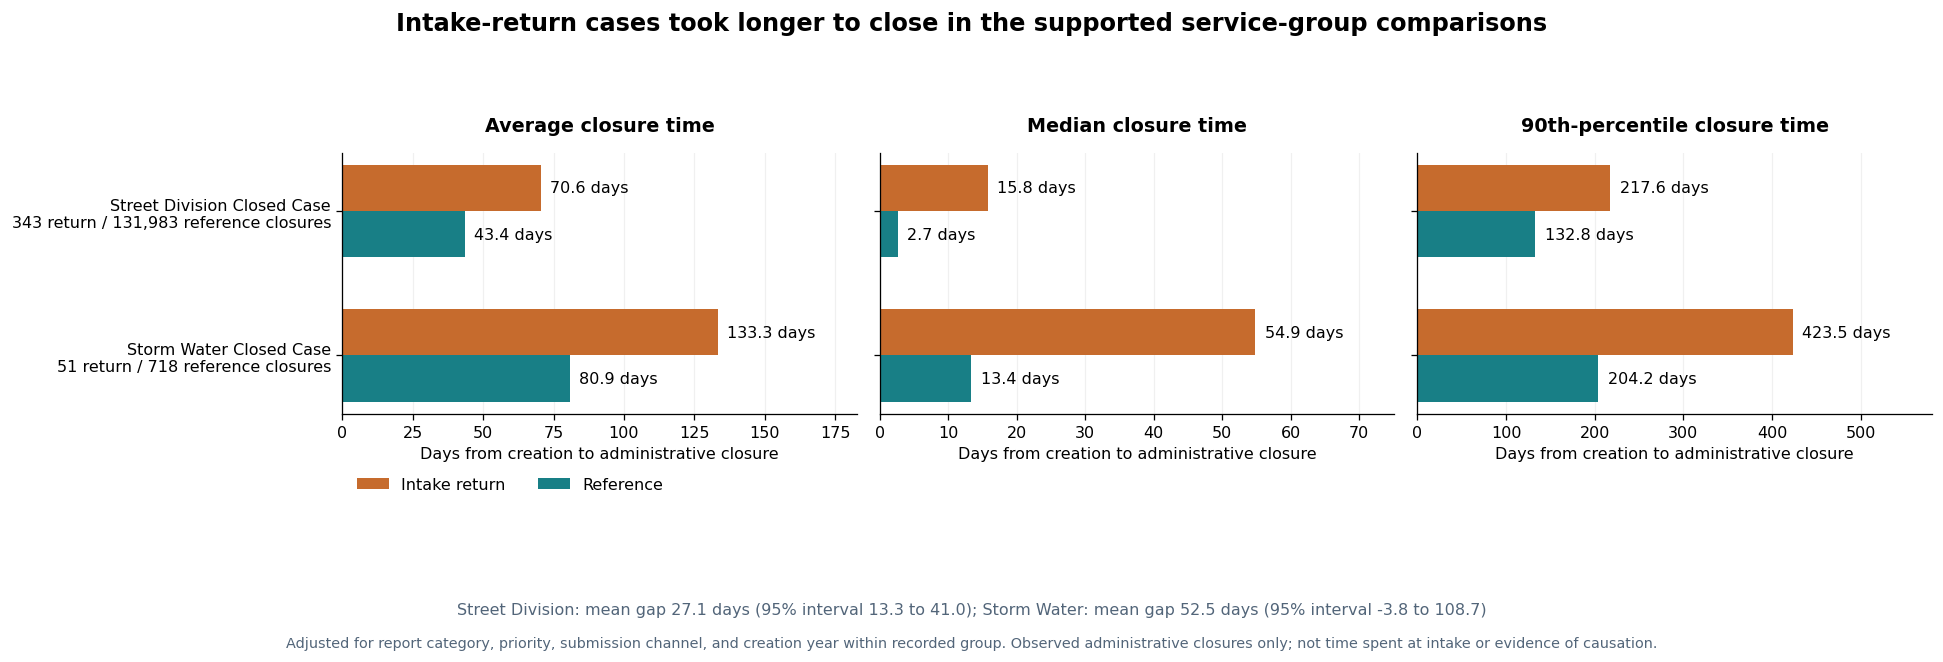

**Numerical values behind the duration comparison**

,service_group,arm,closed_n,adjusted_mean_days,adjusted_median_days,adjusted_p90_days
4,Storm Water Closed Case,Intake return,51,133.34,54.87,423.50
5,Storm Water Closed Case,Reference,718,80.88,13.39,204.19
6,Street Division Closed Case,Intake return,343,70.58,15.81,217.60
7,Street Division Closed Case,Reference,"131,983",43.44,2.66,132.81


In [20]:

FIGURE_DIR=Path('intake_return_figures')
FIGURE_DIR.mkdir(exist_ok=True)
presentation_groups=['Street Division Closed Case','Storm Water Closed Case']
presentation_groups=[g for g in presentation_groups if (
    (differences.service_group.eq(g)) & differences.return_closed_n.ge(50)
    & differences.reference_closed_n.ge(200)).any()]
duration_plot=times.loc[times.service_group.isin(presentation_groups)].copy()
duration_plot.to_csv(FIGURE_DIR/'adjusted_closure_times_by_service_group.csv',index=False)

fig,axes=plt.subplots(1,3,figsize=(17,5.8),sharey=True)
y=np.arange(len(presentation_groups));h=.32
panels=[('adjusted_mean_days','Average closure time'),
        ('adjusted_median_days','Median closure time'),
        ('adjusted_p90_days','90th-percentile closure time')]
for ax,(metric,title) in zip(axes,panels):
    maximum=duration_plot[metric].max()
    for label,color,offset in [('Intake return',RETURN,-h/2),('Reference',REFERENCE,h/2)]:
        vals=duration_plot.loc[duration_plot.arm.eq(label)].set_index('service_group').reindex(presentation_groups)[metric]
        ax.barh(y+offset,vals,height=h,color=color,label=label)
        for yi,v in zip(y+offset,vals):
            ax.text(v+maximum*.025,yi,f'{v:.1f} days',va='center',fontsize=10)
    ax.set_xlim(0,maximum*1.37)
    ax.set_title(title,fontsize=12)
    ax.set_xlabel('Days from creation to administrative closure')
    ax.grid(axis='y',visible=False)

labels=[]
for group in presentation_groups:
    count=differences.loc[differences.service_group.eq(group)].iloc[0]
    labels.append(textwrap.fill(group,28)+f'\n{int(count.return_closed_n):,} return / {int(count.reference_closed_n):,} reference closures')
axes[0].set_yticks(y,labels);axes[0].invert_yaxis()
axes[0].legend(loc='upper left',bbox_to_anchor=(0,-.19),ncol=2,frameon=False)
fig.suptitle('Intake-return cases took longer to close in the supported service-group comparisons',
             fontsize=15,fontweight='semibold',y=.98)
interval_notes=[]
for group in presentation_groups:
    row=differences.loc[differences.service_group.eq(group)].iloc[0]
    short=group.replace(' Closed Case','')
    interval_notes.append(f'{short}: mean gap {row.adjusted_mean_diff:.1f} days (95% interval {row.ci_low:.1f} to {row.ci_high:.1f})')
fig.text(.5,.075,'; '.join(interval_notes),ha='center',fontsize=10,color=NEUTRAL)
fig.text(.5,.025,'Adjusted for report category, priority, submission channel, and creation year within recorded group. '
         'Observed administrative closures only; not time spent at intake or evidence of causation.',
         ha='center',fontsize=9,color=NEUTRAL)
fig.tight_layout(rect=[0,.15,1,.91])
duration_png=FIGURE_DIR/'intake_vs_non_return_closure_times.png'
fig.savefig(duration_png,dpi=240,facecolor='white',bbox_inches='tight')
plt.show()
table(duration_plot[['service_group','arm','closed_n','adjusted_mean_days','adjusted_median_days','adjusted_p90_days']],
      'Numerical values behind the duration comparison')
assert duration_png.is_file()


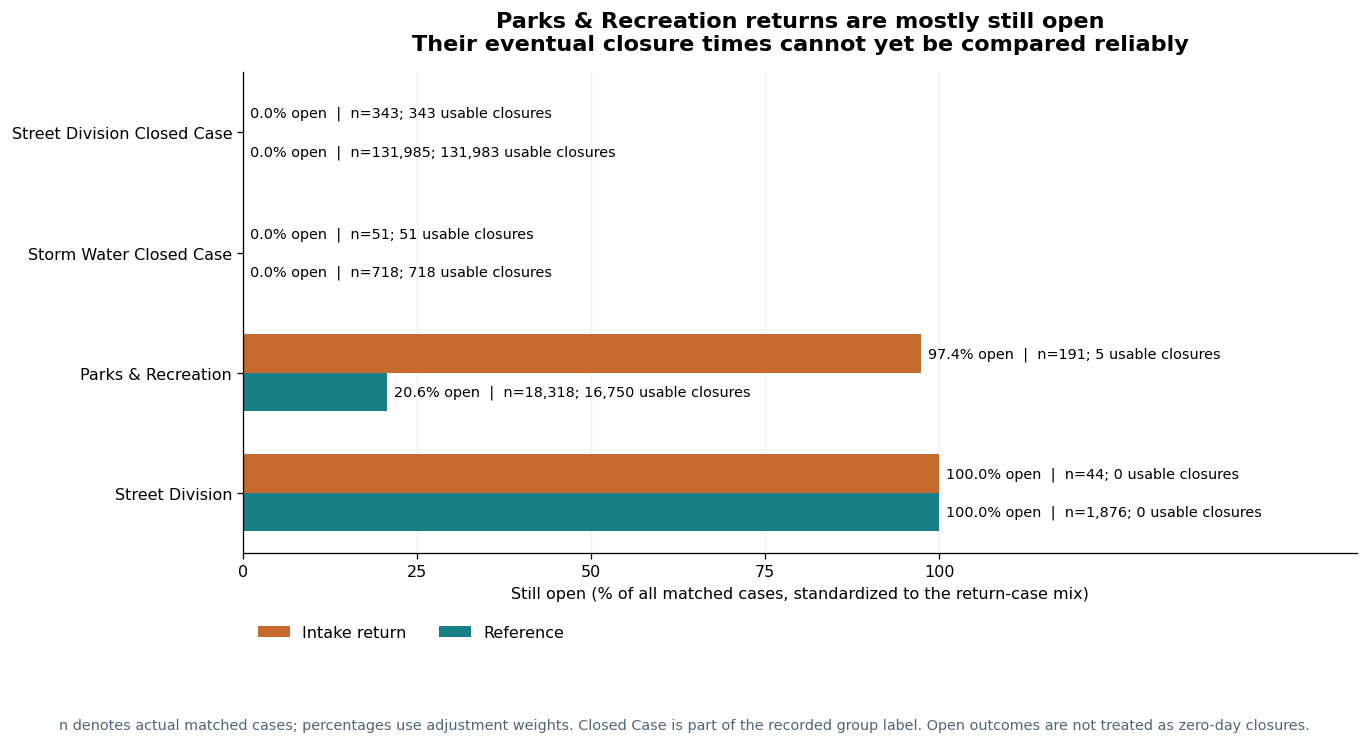

**Numerical values behind the open-case comparison**

,service_group,arm,cases,usable_closures,adjusted_open_pct,adjusted_no_usable_date_pct
4,Storm Water Closed Case,Intake return,51,51,0.00,0.00
5,Storm Water Closed Case,Reference,718,718,0.00,0.00
6,Parks & Recreation,Intake return,191,5,97.38,97.38
7,Parks & Recreation,Reference,"18,318","16,750",20.59,20.59
8,Street Division Closed Case,Intake return,343,343,0.00,0.00
9,Street Division Closed Case,Reference,"131,985","131,983",0.00,0.00
10,Street Division,Intake return,44,0,100.00,100.00
11,Street Division,Reference,"1,876",0,100.00,100.00


Presentation figures saved to: C:\Users\kchri\Desktop\Misroutes_EDA\intake_return_figures


In [21]:

open_plot_groups=['Street Division Closed Case','Storm Water Closed Case','Parks & Recreation','Street Division']
availability_plot=rates.loc[rates.service_group.isin(open_plot_groups)].copy()
availability_plot.to_csv(FIGURE_DIR/'matched_outcomes_by_service_group.csv',index=False)
fig,ax=plt.subplots(figsize=(12,6.6))
y=np.arange(len(open_plot_groups));h=.32
for arm,color,offset in [('Intake return',RETURN,-h/2),('Reference',REFERENCE,h/2)]:
    rows=availability_plot.loc[availability_plot.arm.eq(arm)].set_index('service_group').reindex(open_plot_groups)
    ax.barh(y+offset,rows.adjusted_open_pct,height=h,color=color,label=arm)
    for yi,(_,r) in zip(y+offset,rows.iterrows()):
        n=int(r.cases);closed_n=int(r.usable_closures)
        annotation=f'{r.adjusted_open_pct:.1f}% open  |  n={n:,}; {closed_n:,} usable closures'
        ax.text(r.adjusted_open_pct+1,yi,annotation,va='center',fontsize=9)
ax.set_yticks(y,[textwrap.fill(g,27) for g in open_plot_groups]);ax.invert_yaxis()
ax.set_xlim(0,160);ax.set_xticks([0,25,50,75,100]);ax.grid(axis='y',visible=False)
ax.set_xlabel('Still open (% of all matched cases, standardized to the return-case mix)')
ax.set_title('Parks & Recreation returns are mostly still open\nTheir eventual closure times cannot yet be compared reliably',fontsize=14)
ax.legend(loc='upper left',bbox_to_anchor=(0,-.12),ncol=2,frameon=False)
fig.text(.5,.03,'n denotes actual matched cases; percentages use adjustment weights. '
         'Closed Case is part of the recorded group label. Open outcomes are not treated as zero-day closures.',
         ha='center',fontsize=9,color=NEUTRAL)
fig.tight_layout(rect=[0,.10,1,1])
open_png=FIGURE_DIR/'intake_vs_non_return_open_cases.png'
fig.savefig(open_png,dpi=240,facecolor='white',bbox_inches='tight')
plt.show()
table(availability_plot[['service_group','arm','cases','usable_closures','adjusted_open_pct','adjusted_no_usable_date_pct']],
      'Numerical values behind the open-case comparison')
assert open_png.is_file()
print('Presentation figures saved to:',FIGURE_DIR.resolve())


**Read these figures together.** Among usable, comparable closures, returns have longer administrative closure times. The strongest primary evidence is Street Division Closed Case. Parks & Recreation has an unusually high share of open intake-return records, which prevents a reliable duration comparison. Exact-disposition matching elsewhere in this notebook substantially weakens the mean contrast, so these graphs support staff review rather than a causal claim about intake or a diagnosis of misrouting.

## 11. Presentation-ready findings

The following findings are generated directly from the executed results. Use the figures above with their denominators and conditional-outcome labels intact.

In [22]:
overall=rates.loc[rates.service_group.eq('All supported groups')].set_index('arm')
tm=times.loc[times.service_group.eq('All supported groups')].set_index('arm')
street=differences.loc[differences.service_group.eq('Street Division Closed Case')].iloc[0]
storm=differences.loc[differences.service_group.eq('Storm Water Closed Case')].iloc[0]
street_tm=times.loc[times.service_group.eq('Street Division Closed Case')].set_index('arm')
parks=rates.loc[rates.service_group.eq('Parks & Recreation')].set_index('arm')
disp_s=sensitivity.loc[sensitivity.specification.eq('Add exact text-derived disposition')].iloc[0]
no_ref=sensitivity.loc[sensitivity.specification.eq('References without referral metadata')].iloc[0]
old=sensitivity.loc[sensitivity.specification.eq('Created through 2024')].iloc[0]
quarter=sensitivity.loc[sensitivity.specification.eq('Add exact creation quarter')].iloc[0]
raw_t=raw_overview.set_index('arm').loc['Intake return'];raw_c=raw_overview.set_index('arm').loc['All non-return']
missing_action=int(intake_cases['Action Taken'].isna().sum())
findings=f"""
### What this extract supports

**1. Do intake-return cases have longer administrative lifetimes than similar cases?**  
Among **{int(headline.return_closed_n):,} returns and {int(headline.reference_closed_n):,} references with usable closures in time-supported strata**, the standardized mean creation-to-administrative-closure interval is **{tm.loc['Intake return','adjusted_mean_days']:.1f} versus {tm.loc['Reference','adjusted_mean_days']:.1f} days**, a difference of **{headline.adjusted_mean_diff:.1f} days** (approximate 95% interval **{headline.ci_low:.1f} to {headline.ci_high:.1f}**). The unadjusted difference on this same time-supported sample is {headline.unadjusted_mean_diff:.1f} days. Standardized medians are {tm.loc['Intake return','adjusted_median_days']:.1f} versus {tm.loc['Reference','adjusted_median_days']:.1f} days; 90th percentiles are {tm.loc['Intake return','adjusted_p90_days']:.1f} versus {tm.loc['Reference','adjusted_p90_days']:.1f} days. This is evidence of a conditional association among observed closures. **The all-case lifetime comparison remains unresolved because outcomes are differentially unavailable.**

**2. Which recorded service groups have the strongest evidence?**  
**Street Division Closed Case** supplies the strongest primary duration evidence: **{int(street.return_closed_n):,} return closures and {int(street.reference_closed_n):,} reference closures**, standardized means {street_tm.loc['Intake return','adjusted_mean_days']:.1f} versus {street_tm.loc['Reference','adjusted_mean_days']:.1f} days, a **{street.adjusted_mean_diff:.1f}-day difference** ({street.ci_low:.1f} to {street.ci_high:.1f}). It has {int(group_frequency.loc['Street Division Closed Case','return_cases'])} returns in the full source. The positive contrast persists with creation-quarter matching and older-cohort restrictions, but weakens when matching dispositions. **Storm Water Closed Case** has {int(storm.return_closed_n)} usable matched return closures and {int(storm.reference_closed_n):,} references; its {storm.adjusted_mean_diff:.1f}-day estimate has a wide interval ({storm.ci_low:.1f} to {storm.ci_high:.1f}), including zero. Small groups cannot support a reliable ranking. **Parks & Recreation** is a high-volume outcome-tracking candidate, not a defensible closed-time finding.

**3. How much do open cases and dispositions affect the result?**  
In the full source, **427 of 1,033 returns (41.3%) are open**, compared with {raw_c.open_pct:.1f}% of all non-returns; {int(raw_c.closed_missing_date_n):,} non-return cases are recorded closed without usable closure dates. Exact all-case matching retains **{int(m.return_to_intake.sum()):,} returns ({100*m.return_to_intake.sum()/a.return_to_intake.sum():.1f}%)** and {int((~m.return_to_intake).sum()):,} references. Standardized open percentages are **{overall.loc['Intake return','adjusted_open_pct']:.1f}% versus {overall.loc['Reference','adjusted_open_pct']:.1f}%**, a **{overall.loc['Intake return','adjusted_open_pct']-overall.loc['Reference','adjusted_open_pct']:.1f}-percentage-point gap**. In Parks & Recreation they are **{parks.loc['Intake return','adjusted_open_pct']:.1f}% versus {parks.loc['Reference','adjusted_open_pct']:.1f}%**; only {int(parks.loc['Intake return','usable_closures'])} matched returns have usable closures, insufficient for stratum-level time support. Raw matched mean/median values there must not be treated as representative lifetimes.

Adding exact text-derived disposition reduces the pooled mean contrast to **{disp_s.adjusted_mean_diff_days:.1f} days** ({disp_s.ci_low:.1f} to {disp_s.ci_high:.1f}; {int(disp_s.time_return_n)} usable return closures). Using references without referral metadata yields **{no_ref.adjusted_mean_diff_days:.1f} days** ({no_ref.ci_low:.1f} to {no_ref.ci_high:.1f}). These changed populations and pathways materially affect the result; the attenuation is not a causal decomposition. The through-2024 cohort has an adjusted open gap of {old.return_open_pct-old.reference_open_pct:.1f} points and a conditional time difference of {old.adjusted_mean_diff_days:.1f} days. Exact quarter matching yields {quarter.adjusted_mean_diff_days:.1f} days with {int(quarter.time_return_n)} usable return closures. Two implied age-field refresh dates prevent treating the extract as a certified single-cutoff survival dataset.

**4. What do staff descriptions suggest?**  
Descriptions span repair/resolution, forwarding, duplicates, no-action/jurisdiction decisions, and future/partial work. `Action Taken` is missing for **{missing_action} of 1,033 returns**; only **{int(intake_cases['Referred Department'].notna().sum())}** have a populated referred department. This supports a heterogeneous administrative workflow interpretation and targeted case review. It does not establish which assignment was incorrect, why a specific return occurred, or whether work was physically completed.

**5. What additional City information is required to identify genuine misrouting?**

- Timestamped assignment, acceptance, rejection, intake-return, status, and reason histories, including whether `Case Reason` is overwritten or persists after a handoff.
- The original and receiving service groups, actual team ownership, return rationale, routing rules and jurisdiction at the time, and an independently reviewed definition of an incorrect initial assignment.
- Parent/child, duplicate, re-created, work-order, referral, and receiving-system links, with physical work completion recorded separately from Get It Done closure.
- A documented extract/as-of time for each source segment, formula refresh rules, coverage changes, and reopened-case handling, so open cases can be followed and censored appropriately.
- Baseline severity, location/jurisdiction, workload and resource availability, plus a staff-reviewed sample of returns and comparable non-returns to assess unmeasured selection and label accuracy.

### City staff review priorities

Prioritize **Street Division Closed Case** for dated assignment and closure-disposition review; **Parks & Recreation** for open-record, handoff-acceptance, and reason-maintenance review; and **Storm Water Closed Case** for a smaller, uncertainty-aware sample review. Use the high-volume group/category table above to choose cases. Do not total the mean differences as City delay attributable to intake, equate case lifetime with time at intake, or claim returns caused the differences.
"""
display(Markdown(findings))


### What this extract supports

**1. Do intake-return cases have longer administrative lifetimes than similar cases?**  
Among **399 returns and 145,271 references with usable closures in time-supported strata**, the standardized mean creation-to-administrative-closure interval is **77.9 versus 47.8 days**, a difference of **30.1 days** (approximate 95% interval **16.2 to 44.0**). The unadjusted difference on this same time-supported sample is 53.7 days. Standardized medians are 18.1 versus 3.1 days; 90th percentiles are 231.6 versus 142.2 days. This is evidence of a conditional association among observed closures. **The all-case lifetime comparison remains unresolved because outcomes are differentially unavailable.**

**2. Which recorded service groups have the strongest evidence?**  
**Street Division Closed Case** supplies the strongest primary duration evidence: **343 return closures and 131,983 reference closures**, standardized means 70.6 versus 43.4 days, a **27.1-day difference** (13.3 to 41.0). It has 465 returns in the full source. The positive contrast persists with creation-quarter matching and older-cohort restrictions, but weakens when matching dispositions. **Storm Water Closed Case** has 51 usable matched return closures and 718 references; its 52.5-day estimate has a wide interval (-3.8 to 108.7), including zero. Small groups cannot support a reliable ranking. **Parks & Recreation** is a high-volume outcome-tracking candidate, not a defensible closed-time finding.

**3. How much do open cases and dispositions affect the result?**  
In the full source, **427 of 1,033 returns (41.3%) are open**, compared with 6.1% of all non-returns; 115,089 non-return cases are recorded closed without usable closure dates. Exact all-case matching retains **634 returns (61.4%)** and 165,474 references. Standardized open percentages are **36.3% versus 13.1%**, a **23.1-percentage-point gap**. In Parks & Recreation they are **97.4% versus 20.6%**; only 5 matched returns have usable closures, insufficient for stratum-level time support. Raw matched mean/median values there must not be treated as representative lifetimes.

Adding exact text-derived disposition reduces the pooled mean contrast to **8.6 days** (-7.1 to 24.4; 266 usable return closures). Using references without referral metadata yields **12.1 days** (-2.4 to 26.6). These changed populations and pathways materially affect the result; the attenuation is not a causal decomposition. The through-2024 cohort has an adjusted open gap of 4.1 points and a conditional time difference of 30.7 days. Exact quarter matching yields 28.9 days with 287 usable return closures. Two implied age-field refresh dates prevent treating the extract as a certified single-cutoff survival dataset.

**4. What do staff descriptions suggest?**  
Descriptions span repair/resolution, forwarding, duplicates, no-action/jurisdiction decisions, and future/partial work. `Action Taken` is missing for **503 of 1,033 returns**; only **33** have a populated referred department. This supports a heterogeneous administrative workflow interpretation and targeted case review. It does not establish which assignment was incorrect, why a specific return occurred, or whether work was physically completed.

**5. What additional City information is required to identify genuine misrouting?**

- Timestamped assignment, acceptance, rejection, intake-return, status, and reason histories, including whether `Case Reason` is overwritten or persists after a handoff.
- The original and receiving service groups, actual team ownership, return rationale, routing rules and jurisdiction at the time, and an independently reviewed definition of an incorrect initial assignment.
- Parent/child, duplicate, re-created, work-order, referral, and receiving-system links, with physical work completion recorded separately from Get It Done closure.
- A documented extract/as-of time for each source segment, formula refresh rules, coverage changes, and reopened-case handling, so open cases can be followed and censored appropriately.
- Baseline severity, location/jurisdiction, workload and resource availability, plus a staff-reviewed sample of returns and comparable non-returns to assess unmeasured selection and label accuracy.

### City staff review priorities

Prioritize **Street Division Closed Case** for dated assignment and closure-disposition review; **Parks & Recreation** for open-record, handoff-acceptance, and reason-maintenance review; and **Storm Water Closed Case** for a smaller, uncertainty-aware sample review. Use the high-volume group/category table above to choose cases. Do not total the mean differences as City delay attributable to intake, equate case lifetime with time at intake, or claim returns caused the differences.
